In [28]:
import datetime as dt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import requests
import re
import pickle 
import pickle as pk
import keras
import tensorflow as tf
import os

from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

from keras import layers
from keras.layers import RepeatVector
from keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard
from keras.models import Sequential, Model, load_model
from keras.layers import Input, Dense, Activation, Flatten, Dropout
from keras.layers import SimpleRNN, GRU
from keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Input, LSTM, RepeatVector, TimeDistributed
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

from torchdiffeq import odeint

from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import confusion_matrix
import plotly.graph_objs as go

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp: 
        return pickle.load(inp)

In [5]:
### Visualization 2020 to 2023

df = pd.read_csv("./CSV data/GT/GT_final.csv")
df.head()

start_date = '2020-01-01 00:00:00'
num_rows = len(df)
date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')

df['date'] = date_range
df.to_csv("./CSV data/GT/GT_final_date.csv", index = False)

In [3]:
df = pd.read_csv("./CSV data/GT/GT_final_date.csv")

In [4]:
### spike 처리 

date = df['date']
df = df[df.iloc[:, :-1] < 300]
df = df[df.iloc[:, :-1] > -300]
df['date'] = date

### Neural ODE

In [6]:
def train_enhanced_anomaly_detector(model, train_loader, optimizer, num_epochs, device):
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for x_batch, time_steps in train_loader:
            x_batch = x_batch.to(device)
            time_steps = time_steps.to(device)
            
            # 1. 정상 데이터 처리
            encoded_normal = model.encoder(x_batch, time_steps)
            z0_normal = encoded_normal[:, -1, :]
            reconstructed_normal = model.decoder(z0_normal, time_steps)
            
            # 재구성 손실
            recon_loss = F.mse_loss(reconstructed_normal, x_batch)
            
            # 2. 인공 이상치 생성
            noise_level = min(0. + epoch * 0.01, 0.5)  # 점진적 노이즈 증가
            noise_mask = (torch.rand_like(x_batch[:, :, 0:1]) < 0.2).float()
            noise = torch.randn_like(x_batch) * noise_level * noise_mask
            noisy_x = x_batch + noise
            
            # 이상치 데이터 처리
            encoded_anomaly = model.encoder(noisy_x, time_steps)
            z0_anomaly = encoded_anomaly[:, -1, :]
            reconstructed_anomaly = model.decoder(z0_anomaly, time_steps)
            
            # 3. 특징 대조 손실
            normal_features = encoded_normal.mean(dim=1)
            anomaly_features = encoded_anomaly.mean(dim=1)
            contrast_loss = feature_contrastive_loss(normal_features, anomaly_features, margin=2.0)
            
            # 4. 시간적 일관성 손실
            normal_scores = model(x_batch, time_steps)
            anomaly_scores = model(noisy_x, time_steps)
            temporal_loss = temporal_consistency_loss(normal_scores) + temporal_consistency_loss(anomaly_scores)
            
            # 5. 분류 손실
            class_loss = F.binary_cross_entropy(normal_scores, torch.zeros_like(normal_scores)) + \
                         F.binary_cross_entropy(anomaly_scores, torch.ones_like(anomaly_scores) * 0.9)
            
            # 최종 손실 계산
            loss = 0.4 * recon_loss + 0.3 * contrast_loss + 0.1 * temporal_loss + 0.2 * class_loss
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # 그래디언트 클리핑
            optimizer.step()
            
            total_loss += loss.item()
        
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss/len(train_loader):.6f}")
        

In [7]:
# 통합된 이상 탐지 평가 함수
def evaluate_anomaly_detector(
    model, 
    test_data=None, 
    test_labels=None, 
    test_loader=None,
    device=None, 
    threshold=None,
    threshold_method='auto',
    threshold_percentile=95,
    return_scores=False,
    verbose=True
):

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    model = model.to(device)
    model.eval()
    
    # 입력 검증
    if test_loader is not None and (test_data is not None or test_labels is not None):
        raise ValueError("test_loader와 test_data/test_labels를 동시에 사용할 수 없습니다.")
    
    if test_loader is None and (test_data is None or test_labels is None):
        raise ValueError("test_loader 또는 test_data/test_labels를 제공해야 합니다.")
    
    # 이상 점수 계산
    anomaly_scores = []
    all_labels = []
    
    with torch.no_grad():
        if test_loader is not None:
            # DataLoader 사용 경우
            for batch_data in test_loader:
                if len(batch_data) == 3:  # (x, times, mask)
                    x_batch, times_batch, mask_batch = batch_data
                    x_batch = x_batch.to(device)
                    times_batch = times_batch.to(device)
                    mask_batch = mask_batch.to(device)
                    
                    scores = model.anomaly_score(x_batch, times_batch, mask_batch)
                    anomaly_scores.extend(scores.cpu().numpy())
                else:
                    raise ValueError("DataLoader의 배치 형태가 예상과 다릅니다.")
            
            # test_loader에서 라벨 추출 (별도로 제공되어야 함)
            if test_labels is None:
                raise ValueError("test_loader 사용시 test_labels를 별도로 제공해야 합니다.")
            all_labels = test_labels
            
        else:
            # 직접 데이터 입력 경우
            if isinstance(test_data, np.ndarray):
                test_data = torch.tensor(test_data, dtype=torch.float32)
            
            # 차원 처리
            if test_data.dim() == 2:  # (T, D) → (1, T, D)
                test_data = test_data.unsqueeze(0)
            
            # 시간 벡터 생성
            T = test_data.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_data.shape[0], -1).to(device)
            
            # 마스크 생성
            mask = torch.ones_like(timestamps)
            
            # 데이터를 디바이스로 이동
            test_data = test_data.to(device)
            
            # 이상 점수 계산
            scores = model.anomaly_score(test_data, timestamps, mask)
            anomaly_scores = scores.cpu().numpy()
            all_labels = test_labels
    
    # 점수와 라벨 형태 맞추기
    anomaly_scores = np.array(anomaly_scores)
    all_labels = np.array(all_labels)
    
    # 차원 조정
    if all_labels.ndim == 1 and len(anomaly_scores.shape) > 1 and anomaly_scores.shape[0] == 1:
        # 단일 시퀀스 (1, T)와 벡터 라벨 (T,)
        scores_flat = anomaly_scores.squeeze()
        labels_flat = all_labels
    elif all_labels.ndim == 2:
        # 다중 시퀀스와 2D 라벨
        scores_flat = anomaly_scores.reshape(-1)
        labels_flat = all_labels.reshape(-1)
    elif len(anomaly_scores.shape) > 1:
        # 다중 시퀀스와 1D 라벨 - 윈도우별 최대값 사용
        scores_flat = np.max(anomaly_scores, axis=1) if anomaly_scores.ndim > 1 else anomaly_scores
        labels_flat = all_labels
    else:
        scores_flat = anomaly_scores
        labels_flat = all_labels
    
    # 임계값 설정
    if threshold is None:
        if threshold_method == 'percentile':
            threshold = np.percentile(scores_flat, threshold_percentile)
        elif threshold_method == 'normal_based':
            # 정상 데이터 기반 임계값
            normal_scores = scores_flat[labels_flat == 0]
            if len(normal_scores) > 0:
                threshold = np.mean(normal_scores) + 2 * np.std(normal_scores)
            else:
                threshold = np.percentile(scores_flat, 95)
        elif threshold_method == 'auto':
            # 자동 선택: 정상 데이터가 충분하면 normal_based, 아니면 percentile
            normal_scores = scores_flat[labels_flat == 0]
            if len(normal_scores) > len(scores_flat) * 0.7:  # 정상 데이터가 70% 이상
                threshold = np.mean(normal_scores) + 2 * np.std(normal_scores)
            else:
                threshold = np.percentile(scores_flat, threshold_percentile)
        else:
            raise ValueError(f"지원하지 않는 threshold_method: {threshold_method}")
    
    # 예측 생성
    predictions = (scores_flat > threshold).astype(int)
    
    # 성능 지표 계산
    metrics = {}
    
    try:
        # 기본 분류 지표
        metrics['accuracy'] = accuracy_score(labels_flat, predictions)
        metrics['precision'] = precision_score(labels_flat, predictions, average='binary', zero_division=0)
        metrics['recall'] = recall_score(labels_flat, predictions, average='binary', zero_division=0)
        metrics['f1'] = f1_score(labels_flat, predictions, average='binary', zero_division=0)
        
        # ROC-AUC (레이블이 다양한 경우에만)
        if len(np.unique(labels_flat)) > 1:
            metrics['auc'] = roc_auc_score(labels_flat, scores_flat)
        else:
            metrics['auc'] = None
            
    except Exception as e:
        if verbose:
            print(f"지표 계산 중 오류 발생: {e}")
        metrics['accuracy'] = 0.0
        metrics['precision'] = 0.0
        metrics['recall'] = 0.0
        metrics['f1'] = 0.0
        metrics['auc'] = None
    
    # 추가 정보
    metrics['threshold'] = threshold
    metrics['threshold_method'] = threshold_method
    metrics['num_samples'] = len(labels_flat)
    metrics['num_anomalies'] = np.sum(labels_flat)
    metrics['num_predicted_anomalies'] = np.sum(predictions)
    
    # 이상 점수 반환 옵션
    if return_scores:
        metrics['anomaly_scores'] = scores_flat
        metrics['predictions'] = predictions
        metrics['labels'] = labels_flat
    
    # 결과 출력
    if verbose:
        print(f"=== 이상 탐지 평가 결과 ===")
        print(f"Threshold ({threshold_method}): {threshold:.4f}")
        print(f"Accuracy: {metrics['accuracy']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall: {metrics['recall']:.4f}")
        print(f"F1 Score: {metrics['f1']:.4f}")
        if metrics['auc'] is not None:
            print(f"AUC: {metrics['auc']:.4f}")
        print(f"Samples: {metrics['num_samples']}, "
              f"True Anomalies: {metrics['num_anomalies']}, "
              f"Predicted: {metrics['num_predicted_anomalies']}")
    
    return metrics

In [8]:
def plot_spike_detection_for_variable(x, time_steps, anomaly_scores, var_idx=0, threshold=None, sample_idx=0, percentile=95):
    """
    x: (batch, seq_len, input_dim) - 입력 시계열
    time_steps: (batch, seq_len) - 시간 정보
    anomaly_scores: (batch, seq_len) - 모델 출력 anomaly score
    var_idx: int - 시각화할 변수 인덱스 (ex. 0~127)
    sample_idx: int - 배치 중 어떤 시계열을 볼지 (기본값: 0)
    threshold: float - anomaly 판단 기준값. 없으면 percentile 기반 계산
    percentile: float - threshold를 anomaly_scores의 상위 몇 %로 지정할지
    """

    # Tensor → NumPy
    x_np = x.detach().cpu().numpy()
    time_np = time_steps.detach().cpu().numpy()
    score_np = anomaly_scores.detach().cpu().numpy()

    # 하나의 시계열 추출
    values = x_np[sample_idx, :, var_idx]
    times = time_np[sample_idx]
    scores = score_np[sample_idx]

    # threshold 계산 (percentile 기반 or 수동 입력)
    if threshold is None:
        threshold = np.percentile(scores, percentile)
    
    # spike 위치
    spikes = scores > threshold

    # 시각화
    fig, ax1 = plt.subplots(figsize=(14, 5))

    # 실제 값 plot
    ax1.set_title(f"Spike Detection for Variable {var_idx}")
    ax1.plot(times, values, label=f'Variable {var_idx} Value', color='blue', marker='o')
    ax1.set_xlabel("Time")
    ax1.set_ylabel("Variable Value", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    # spike 점 찍기
    ax1.scatter(times[spikes], values[spikes], color='red', label='Detected Spikes', zorder=5)

    # anomaly score plot (우측 축)
    ax2 = ax1.twinx()
    ax2.plot(times, scores, color='orange', linestyle='--', label='Anomaly Score')
    ax2.axhline(threshold, color='gray', linestyle=':', label='Threshold')
    ax2.set_ylabel("Anomaly Score", color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')

    # 범례 정리
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 간단 출력
    print("Total spikes detected:", spikes.sum())
    print("Threshold used:", threshold)


In [9]:
def train_irregular_ode(model, data_dict, num_epochs=30):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    
    # Optimizer setup
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )
    
    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=True
    )
    
    # Training
    model.train()
    history = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        epoch_flow_loss = 0
        
        for batch_idx, (x_batch, times_batch, mask_batch) in enumerate(data_dict['train_loader']):
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            optimizer.zero_grad()
            
            # Forward pass
            outputs = model(x_batch, times_batch, mask_batch)
            losses = outputs["losses"]
            
            # Backward pass
            losses["total_loss"].backward()
            
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            # Accumulate losses
            epoch_loss += losses["total_loss"].item()
            epoch_recon_loss += losses["recon_loss"].item()
            epoch_kl_loss += losses["kl_loss"].item()
            epoch_flow_loss += losses["flow_loss"].item()
        
        # Average losses per epoch
        n_batches = len(data_dict['train_loader'])
        avg_loss = epoch_loss / n_batches
        avg_recon_loss = epoch_recon_loss / n_batches
        avg_kl_loss = epoch_kl_loss / n_batches
        avg_flow_loss = epoch_flow_loss / n_batches
        
        # Learning rate adjustment
        scheduler.step(avg_loss)
        
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Loss: {avg_loss:.4f}, "
              f"Recon: {avg_recon_loss:.4f}, "
              f"KL: {avg_kl_loss:.4f}, "
              f"Flow: {avg_flow_loss:.4f}")
        
        history.append({
            'epoch': epoch + 1,
            'total_loss': avg_loss,
            'recon_loss': avg_recon_loss,
            'kl_loss': avg_kl_loss,
            'flow_loss': avg_flow_loss
        })
    
    # Evaluation
    model.eval()
    anomaly_scores = []
    
    with torch.no_grad():
        for x_batch, times_batch, mask_batch in data_dict['test_loader']:
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            # Calculate anomaly scores
            scores = model.anomaly_score(x_batch, times_batch, mask_batch)
            anomaly_scores.extend(scores)
    
    anomaly_scores = np.array(anomaly_scores)
    
    # Convert labels to numpy and check dimensions
    if isinstance(data_dict['lab_tst'], torch.Tensor):
        test_labels = data_dict['lab_tst'].cpu().numpy()
    else:
        test_labels = np.array(data_dict['lab_tst'])
    
    # Adjust dimensions
    if test_labels.ndim > 1:
        test_labels = test_labels.flatten()
    if anomaly_scores.ndim > 1:
        anomaly_scores = anomaly_scores.flatten()
    
    # Match sizes (if lengths differ)
    min_len = min(len(test_labels), len(anomaly_scores))
    test_labels = test_labels[:min_len]
    anomaly_scores = anomaly_scores[:min_len]
    
    # Debug information
    print(f"Test labels shape: {test_labels.shape}")
    print(f"Anomaly scores shape: {anomaly_scores.shape}")
    print(f"Test labels unique values: {np.unique(test_labels)}")
    print(f"Anomaly scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
    
    # Set threshold (90th percentile)
    threshold = np.percentile(anomaly_scores, 90)
    predictions = (anomaly_scores > threshold).astype(int)
    
    # Calculate performance metrics
    metrics = {}
    
    try:
        # Calculate AUC (check binary classification)
        if len(np.unique(test_labels)) == 2:
            metrics['auc'] = roc_auc_score(test_labels, anomaly_scores)
        else:
            print(f"Warning: Not binary classification. Unique labels: {np.unique(test_labels)}")
            metrics['auc'] = None
        
        # Other metrics
        metrics['f1'] = f1_score(test_labels, predictions, average='binary')
        metrics['precision'] = precision_score(test_labels, predictions, average='binary', zero_division=0)
        metrics['recall'] = recall_score(test_labels, predictions, average='binary', zero_division=0)
        metrics['accuracy'] = accuracy_score(test_labels, predictions)
        
        print(f"AUC: {metrics['auc']:.4f}" if metrics['auc'] else "AUC: N/A")
        print(f"F1 Score: {metrics['f1']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall: {metrics['recall']:.4f}")
        print(f"Accuracy: {metrics['accuracy']:.4f}")
        
    except Exception as e:
        print(f"Error in metrics calculation: {e}")
        metrics = {
            'auc': None,
            'f1': 0.0,
            'precision': 0.0,
            'recall': 0.0,
            'accuracy': 0.0
        }
    
    # Additional information
    metrics.update({
        'threshold': threshold,
        'anomaly_scores': anomaly_scores,
        'predictions': predictions,
        'test_labels': test_labels
    })
    
    return model, history, metrics

In [10]:
class ProbabilisticDecoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim * 2)
        )
        
        # 가중치 초기화
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, z):
        # 디코딩
        out = self.decoder(z)
        
        # 출력을 mean과 log variance로 분리
        mean, logvar = torch.chunk(out, 2, dim=-1)
        
        # log variance 클램핑
        logvar = torch.clamp(logvar, min=-20, max=20)
        
        return mean, logvar

In [28]:
# ODE-RNN/GRU-D + Time2Vec + Conditional Flow (최종)

class Time2Vec(nn.Module):
    def __init__(self, out_dim, num_frequencies=4):
        super().__init__()
        self.out_dim = out_dim
        self.num_frequencies = num_frequencies
        
        # Linear component
        self.linear = nn.Linear(1, 1)
        
        # Periodic components with multiple frequencies
        self.frequencies = nn.Parameter(torch.randn(num_frequencies) * 0.1)
        
        # 출력 차원을 정확히 맞추기 위해 계산
        periodic_dim = out_dim - 1  # 전체 차원에서 linear 차원(1)을 뺌
        self.periodic = nn.Linear(1, periodic_dim)
        
        print(f"Time2Vec initialized with:")
        print(f"- Total output dimension: {out_dim}")
        print(f"- Linear component dimension: 1")
        print(f"- Periodic component dimension: {periodic_dim}")
        
    def forward(self, t):
        # Linear component
        v1 = self.linear(t)  # (B, T, 1)
        
        # Periodic component
        periodic = torch.sin(self.frequencies[0] * self.periodic(t))  # (B, T, out_dim-1)
        
        # Concatenate and verify dimension
        output = torch.cat([v1, periodic], dim=-1)  # (B, T, out_dim)
        assert output.size(-1) == self.out_dim, \
            f"Expected output dimension {self.out_dim}, got {output.size(-1)}"
        
        return output

class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, time_emb_dim=8):
        super().__init__()
        self.time2vec = Time2Vec(time_emb_dim)
        
        # 입력 차원 계산 및 확인
        self.input_dim = input_dim
        self.time_emb_dim = time_emb_dim
        self.total_input_dim = input_dim + time_emb_dim
        
        print(f"Initializing ODERNNEncoder with:")
        print(f"- Input dimension: {input_dim}")
        print(f"- Time embedding dimension: {time_emb_dim}")
        print(f"- Total input dimension: {self.total_input_dim}")
        
        self.rnn = nn.GRU(self.total_input_dim, hidden_dim, batch_first=True)
        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)
        
    def forward(self, x, times, mask=None):
        # 입력 차원 확인
        print(f"Input shape: {x.shape}")
        
        # 시간 임베딩
        t_emb = self.time2vec(times.unsqueeze(-1))  # (B, T, time_emb_dim)
        print(f"Time embedding shape: {t_emb.shape}")
        
        # 입력과 시간 임베딩 결합
        x_cat = torch.cat([x, t_emb], dim=-1)  # (B, T, input_dim + time_emb_dim)
        print(f"Concatenated shape: {x_cat.shape}")
        
        # 차원 검증
        assert x_cat.size(-1) == self.total_input_dim, \
            f"Expected input dimension {self.total_input_dim}, got {x_cat.size(-1)}"
        
        # RNN 처리
        h, _ = self.rnn(x_cat)  # (B, T, hidden_dim)
        h_last = h[:, -1]  # (B, hidden_dim)
        
        # 잠재 공간으로 매핑
        mu = self.mu(h_last)  # (B, latent_dim)
        logvar = self.logvar(h_last)  # (B, latent_dim)
        
        # 잠재 변수 샘플링
        z0 = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        
        return z0, mu, logvar

class IrregularTimeSeriesAnomalyDetector(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden_dim=64, flow_layers=4, time_emb_dim=8, beta=0.1):
        super().__init__()
        
        # 차원이 짝수인지 확인
        if latent_dim % 2 != 0:
            latent_dim += 1
            print(f"Adjusted latent_dim to {latent_dim} to ensure it's even.")
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.time_emb_dim = time_emb_dim
        self.beta = beta
        self.temperature = 0.1  
        
        # 개선: 동적 anomaly_weight 설정
        self.anomaly_weight = 2.5  # 기본값을 낮춤 (5.0 → 2.5)
        self.adaptive_weight = True  # 적응적 가중치 사용 여부
        
        # 개선: 섹션별 가중치 저장
        self.section_weights = {
            'no_anomaly': 2.0,      # 이상치 없는 섹션
            'rare_anomaly': 8.0,    # 드문 이상치 (5% 미만)
            'moderate_anomaly': 5.0, # 보통 수준 (5-20%)
            'high_anomaly': 3.0     # 높은 이상치 (20% 이상)
        }
        
        # 인코더 (ODE-RNN + Time2Vec)
        self.encoder = ODERNNEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            latent_dim=latent_dim,
            time_emb_dim=time_emb_dim
        )
        
        # ODE 함수 (Time2Vec 포함)
        self.odefunc = ODEFunc(
            latent_dim=latent_dim,
            hidden_dim=hidden_dim,
            time_emb_dim=time_emb_dim
        )
        
        # 디코더
        self.decoder = ProbabilisticDecoder(
            latent_dim=latent_dim,
            output_dim=input_dim,
            hidden_dim=hidden_dim
        )
        
        # Flow 모델
        self.flow = SimpleFlow(dim=latent_dim, n_layers=flow_layers)
        
        # 사전 확률 분포 파라미터
        self.register_buffer('prior_mean', torch.zeros(latent_dim))
        self.register_buffer('prior_logvar', torch.zeros(latent_dim))
        
        # 개선: 메모리 모듈 추가 (정상 패턴 저장)
        self.memory_size = 100
        self.register_buffer('normal_memory', torch.randn(self.memory_size, latent_dim) * 0.1)
        self.memory_ptr = 0
        
    def set_anomaly_weight(self, weight):
        """anomaly_weight 설정"""
        self.anomaly_weight = weight
        print(f"anomaly_weight set to: {weight}")
    
    def set_section_weight(self, section_type):
        """섹션 유형에 따른 가중치 설정"""
        if section_type in self.section_weights:
            self.anomaly_weight = self.section_weights[section_type]
            print(f"Section type '{section_type}' detected, weight set to: {self.anomaly_weight}")
        else:
            print(f"Unknown section type: {section_type}, using default weight: {self.anomaly_weight}")
    
    def analyze_section_characteristics(self, test_labels):
        """섹션 특성 분석 및 적절한 가중치 설정"""
        if test_labels is None:
            return "unknown"
            
        total_samples = len(test_labels)
        anomaly_samples = np.sum(test_labels)
        anomaly_ratio = anomaly_samples / total_samples
        
        print(f"Section analysis: {total_samples} samples, {anomaly_samples} anomalies ({anomaly_ratio:.4f})")
        
        if anomaly_ratio == 0:
            section_type = "no_anomaly"
        elif anomaly_ratio < 0.05:
            section_type = "rare_anomaly"
        elif anomaly_ratio < 0.2:
            section_type = "moderate_anomaly"
        else:
            section_type = "high_anomaly"
        
        self.set_section_weight(section_type)
        return section_type
        
    def encode(self, x, times, mask=None):
        return self.encoder(x, times, mask)
        
    def decode(self, z0, times):
        if times.dim() > 1:
            times = times[0]
        
        times, indices = torch.sort(times)
        
        zt = odeint(
            self.odefunc,
            z0,
            times,
            method='dopri5',
            rtol=1e-3,
            atol=1e-4
        )
        
        zt = zt.permute(1, 0, 2)
        mu, logvar = self.decoder(zt)
        
        return mu, logvar
        
    def temporal_contrastive_loss(self, z_normal, z_augmented, times, temperature=0.1):
        """
        시간적 연속성을 고려한 대조 학습
        """
        # L2 정규화
        z_normal = F.normalize(z_normal, dim=-1)
        z_augmented = F.normalize(z_augmented, dim=-1)
        
        # 시간 차이에 따른 가중치 계산
        time_diff = torch.abs(times[:, 1:] - times[:, :-1])
        time_weights = torch.exp(-time_diff)  # 시간이 가까울수록 가중치가 큼
        
        # 유사도 계산
        similarity = torch.mm(z_normal, z_augmented.t()) / temperature
        
        # 시간적 연속성을 고려한 loss
        temporal_loss = 0
        for i in range(z_normal.size(0)-1):
            if i < time_weights.size(1):
                weight = time_weights[0, i]
                temporal_loss += weight * F.cross_entropy(
                    similarity[i:i+1], 
                    torch.tensor([i], device=z_normal.device)
                )
        
        return temporal_loss / (z_normal.size(0) - 1)

    def compute_loss(self, x, times, recon_mu, recon_logvar, mu, logvar, z_flow, log_det, mask=None):
        device = x.device
        batch_size = x.shape[0]
        
        # 기존 loss들
        if mask is not None:
            mask_expanded = mask.unsqueeze(-1).expand_as(x)
            recon_error = (recon_mu - x) ** 2
            recon_loss = (recon_error * mask_expanded).sum() / (mask_expanded.sum() + 1e-8)
        else:
            recon_loss = F.mse_loss(recon_mu, x, reduction='mean')
        
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
        
        if z_flow is not None:
            flow_loss = 0.5 * torch.sum(z_flow**2) / batch_size
        else:
            flow_loss = torch.tensor(0.0, device=device)
        
        # 데이터 증강 및 시간적 대조 학습
        if self.training and batch_size > 1:
            # 노이즈 증강
            noise_factor = 0.01
            x_augmented = x + torch.randn_like(x) * noise_factor
            
            # 증강된 데이터의 잠재 표현
            z0_aug, _, _ = self.encode(x_augmented, times, mask)
            
            # 시간적 대조 학습 loss
            contrast_loss = self.temporal_contrastive_loss(mu, z0_aug, times)
        else:
            contrast_loss = torch.tensor(0.0, device=device)
        
        # 개선: 더 강화된 이상치 인식 손실
        anomaly_loss = self.compute_enhanced_anomaly_loss(x, recon_mu, recon_logvar, mu)

        total_loss = (
            recon_loss + 
            self.beta * kl_loss + 
            0.01 * flow_loss + 
            0.2 * contrast_loss +
            0.15 * anomaly_loss  # 가중치 증가 (0.1 → 0.15)
        )
        
        return {
            'total_loss': total_loss,
            'recon_loss': recon_loss,
            'kl_loss': kl_loss,
            'flow_loss': flow_loss,
            'contrast_loss': contrast_loss,
            'anomaly_loss': anomaly_loss
        }

    def compute_enhanced_anomaly_loss(self, x, recon_mu, recon_logvar, mu):
        """개선된 이상치 감지 손실 함수"""
        # 재구성 오차 계산
        recon_error = torch.abs(x - recon_mu)
        
        # 동적 임계값 계산 (더 민감하게)
        mean_error = torch.mean(recon_error, dim=(0, 1))
        std_error = torch.std(recon_error, dim=(0, 1))
        threshold = mean_error + 1.5 * std_error  # 2 → 1.5로 낮춤 (더 민감하게)
        
        # 이상치 가중치 계산 (더 세밀하게)
        anomaly_weights = torch.where(
            recon_error > threshold.unsqueeze(0).unsqueeze(0),
            torch.ones_like(recon_error) * self.anomaly_weight,
            torch.ones_like(recon_error) * 0.5  # 정상 데이터에 대한 가중치도 조정
        )
        
        # 가중치가 적용된 재구성 손실
        weighted_loss = torch.mean(recon_error * anomaly_weights)
        
        # 추가: 잠재 공간에서의 이상치 탐지
        latent_anomaly = torch.mean(torch.abs(mu), dim=-1)
        latent_threshold = torch.mean(latent_anomaly) + torch.std(latent_anomaly)
        latent_weights = torch.where(
            latent_anomaly > latent_threshold,
            torch.ones_like(latent_anomaly) * self.anomaly_weight,
            torch.ones_like(latent_anomaly)
        )
        latent_loss = torch.mean(latent_anomaly * latent_weights)
        
        return weighted_loss + 0.1 * latent_loss
    
    def forward(self, x, times, mask=None):
        if times.dim() == 1:
            times = times.unsqueeze(0).expand(x.size(0), -1)
        
        unique_times = torch.linspace(0, 1, times.size(1)).to(times.device)
        
        z0, mu, logvar = self.encode(x, times, mask)
        z_flow, log_det = self.flow(z0)
        recon_mu, recon_logvar = self.decode(z0, unique_times)
        
        losses = self.compute_loss(x, times, recon_mu, recon_logvar, mu, logvar, z_flow, log_det, mask)
        
        return {
            'z0': z0,
            'mu': mu,
            'logvar': logvar,
            'z_flow': z_flow,
            'log_det': log_det,
            'recon_mu': recon_mu,
            'recon_logvar': recon_logvar,
            'losses': losses
        }
        
    def anomaly_score(self, x, times, mask=None):
        self.eval()
        
        with torch.no_grad():
            outputs = self.forward(x, times, mask)
            
            # 1. 개선된 재구성 오차 (시계열 특성 고려)
            recon_error = torch.abs(x - outputs['recon_mu'])
            std = torch.exp(0.5 * outputs['recon_logvar']) + 1e-6
            
            # Point-wise anomaly score with temporal smoothing
            pointwise_scores = recon_error / std
            
            # Temporal smoothing (이동평균)
            kernel_size = min(5, x.shape[1])
            if kernel_size > 1:
                padding = kernel_size // 2
                pointwise_scores = F.avg_pool1d(
                    pointwise_scores.transpose(1, 2), 
                    kernel_size, stride=1, padding=padding
                ).transpose(1, 2)
            
            if mask is not None:
                mask_expanded = mask.unsqueeze(-1)
                pointwise_scores = pointwise_scores * mask_expanded
            
            # Feature-wise aggregation with temporal attention
            time_diff = torch.abs(times[:, 1:] - times[:, :-1])
            time_weights = torch.exp(-time_diff)  # 시간이 가까울수록 가중치가 큼
            time_weights = F.pad(time_weights, (0, 1), value=1.0)
            
            # 5. 특성별 점수 계산
            feature_scores = pointwise_scores * time_weights.unsqueeze(-1)
            
            # 6. 시퀀스 레벨 통계 계산
            max_scores = torch.max(feature_scores, dim=1)[0]  # (B, F)
            mean_scores = torch.mean(feature_scores, dim=1)   # (B, F)
            std_scores = torch.std(feature_scores, dim=1)     # (B, F)
            
            # 7. KL 발산 점수 계산
            kl_scores = 0.5 * torch.sum(
                outputs['mu'].pow(2) + torch.exp(outputs['logvar']) - outputs['logvar'] - 1,
                dim=-1
            ).unsqueeze(-1)

            # 3. Flow-based density score
            flow_scores = 0.5 * torch.sum(outputs['z_flow']**2, dim=-1).unsqueeze(-1)  # (B, 1)
            
            # 개선: 더 민감한 동적 임계값
            dynamic_threshold = mean_scores + 1.5 * std_scores  # 2 → 1.5로 낮춤

            # 개선: 가중치 조정
            final_scores = (
                0.40 * max_scores +     # 최대 재구성 오차 (0.35 → 0.40)
                0.25 * mean_scores +    # 평균 재구성 오차
                0.15 * std_scores +     # 재구성 오차 변동성
                0.10 * kl_scores.expand(-1, self.input_dim) +  # KL 발산 (0.15 → 0.10)
                0.10 * flow_scores.expand(-1, self.input_dim)  # Flow 밀도
            )
            
            # 개선: 더 세밀한 이상치 마스킹
            anomaly_mask = final_scores > dynamic_threshold
            final_scores = torch.where(
                anomaly_mask,
                final_scores * self.anomaly_weight,
                final_scores * 0.8  # 정상 데이터에 대한 가중치도 조정
            )
            
            # 12. 시퀀스 레벨 점수로 변환
            sequence_scores = torch.mean(final_scores, dim=-1)  # (B,)
            
            # 13. 점수 정규화 (개선된 방식)
            min_score = sequence_scores.min()
            max_score = sequence_scores.max()
            if max_score > min_score:
                sequence_scores = (sequence_scores - min_score) / (max_score - min_score)
            else:
                sequence_scores = torch.zeros_like(sequence_scores)
            
            return sequence_scores.cpu().numpy()

class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, time_emb_dim=8):
        super().__init__()
        self.time2vec = Time2Vec(time_emb_dim)
        self.rnn = nn.GRU(input_dim + time_emb_dim, hidden_dim, batch_first=True)
        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)
    def forward(self, x, times, mask=None):
        t_emb = self.time2vec(times.unsqueeze(-1))  # (B, T, time_emb_dim)
        x_cat = torch.cat([x, t_emb], dim=-1)
        h, _ = self.rnn(x_cat)
        h_last = h[:, -1]
        mu = self.mu(h_last)
        logvar = self.logvar(h_last)
        z0 = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return z0, mu, logvar

class ODEFunc(nn.Module):
    def __init__(self, latent_dim, hidden_dim, time_emb_dim=8):
        super().__init__()
        self.time2vec = Time2Vec(time_emb_dim)
        
        # 시간 임베딩과 상태를 결합한 네트워크
        self.net = nn.Sequential(
            nn.Linear(latent_dim + time_emb_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, latent_dim)
        )
        
    def forward(self, t, z):
        # 시간 임베딩
        t_tensor = t.reshape(1, 1).repeat(z.size(0), 1)
        t_emb = self.time2vec(t_tensor)
        
        # 상태와 시간 임베딩 결합
        z_t = torch.cat([z, t_emb], dim=1)
        
        # 속도장 계산
        dz_dt = self.net(z_t)
        return dz_dt

class ProbabilisticDecoder(nn.Module):
    def __init__(self, latent_dim, output_dim, hidden_dim):
        super().__init__()
        # 더 깊은 네트워크와 정규화 추가
        self.decoder_net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),  # Layer Normalization 추가
            nn.ReLU(),
            nn.Dropout(0.1),  # Dropout 추가
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
        )
        
        # 출력 레이어 분리 및 초기화 개선
        self.mu_net = nn.Linear(hidden_dim, output_dim)
        self.logvar_net = nn.Linear(hidden_dim, output_dim)
        
        # 가중치 초기화
        self._init_weights()

    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
    
    def forward(self, z):
        h = self.decoder_net(z)
        mu = self.mu_net(h)
        logvar = self.logvar_net(h)
        # 분산의 범위를 더 넓게 설정
        logvar = torch.clamp(logvar, -20, 2)
        return mu, logvar
    

class SimpleFlow(nn.Module):
    def __init__(self, dim, n_layers=2):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError(f"Dimension must be even, got {dim}")
            
        self.layers = nn.ModuleList()
        for _ in range(n_layers):
            self.layers.append(AffineCoupling(dim))
            
    def forward(self, z):
        log_det = torch.zeros(z.size(0), device=z.device)
        for layer in self.layers:
            z, ldj = layer(z)
            log_det += ldj
        return z, log_det

class AffineCoupling(nn.Module):
    def __init__(self, dim, hidden_dim=64):
        super().__init__()
        self.dim = dim
        assert dim % 2 == 0, "dim must be even"
        
        self.net = nn.Sequential(
            nn.Linear(dim // 2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, dim)
        )
    
    def forward(self, x, reverse=False):
        x1, x2 = torch.chunk(x, 2, dim=1)
        h = self.net(x1)
        shift, scale = torch.chunk(h, 2, dim=1)
        scale = torch.tanh(scale)
        
        if not reverse:
            y2 = x2 * torch.exp(scale) + shift
        else:
            y2 = (x2 - shift) * torch.exp(-scale)
            
        y = torch.cat([x1, y2], dim=1)
        log_det = scale.sum(dim=1)
        
        if reverse:
            log_det = -log_det
            
        return y, log_det

### Open dataset

1. SMD

In [ ]:
### SMD 
import kagglehub
import shutil
import os
from datasets.SMD.preprocess_SMD import SMD_Dataset  

# Download latest version
path = kagglehub.dataset_download("mgusat/smd-onmiad")

print("Path to dataset files:", path)

# 현재 경로 (KaggleHub 캐시)
source_path = "/Users/jieun/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1"
# 원하는 경로 (예: ./data/SMD)
destination_path = "./datasets/SMD"

os.makedirs(destination_path, exist_ok=True)

for item in os.listdir(source_path):
    s = os.path.join(source_path, item)
    d = os.path.join(destination_path, item)
    if os.path.isdir(s):
        shutil.copytree(s, d, dirs_exist_ok=True)
    else:
        shutil.copy2(s, d)

print("✅ SMD 데이터 복사 완료:", destination_path)

In [14]:
def prepare_smd_data(x_trn, x_tst, lab_tst, batch_size=32):
    # 데이터 형태 확인
    print(f"Original data shapes:")
    print(f"x_trn: {x_trn.shape}, x_tst: {x_tst.shape}, lab_tst: {lab_tst.shape}")
    
    # 데이터 정규화 (Min-Max 스케일링)
    def min_max_scaler(data):
        data_reshaped = data.reshape(-1, data.shape[-1])
        min_vals = np.min(data_reshaped, axis=0)
        max_vals = np.max(data_reshaped, axis=0)
        scaled = (data_reshaped - min_vals) / (max_vals - min_vals + 1e-8)
        return scaled.reshape(data.shape), min_vals, max_vals
    
    # 학습 데이터 정규화
    x_trn_norm, min_vals, max_vals = min_max_scaler(x_trn)
    x_tst_norm = (x_tst.reshape(-1, x_tst.shape[-1]) - min_vals) / (max_vals - min_vals + 1e-8)
    x_tst_norm = x_tst_norm.reshape(x_tst.shape)
    
    # 데이터가 2D인 경우 3D로 변환 (시계열 윈도우 생성)
    if len(x_trn.shape) == 2:  # (samples, features)
        print("Converting 2D data to 3D windows...")
        window_size = min(50, x_trn.shape[0] // 10)  # 적절한 윈도우 크기 설정
        
        # 윈도우 생성 함수
        def create_windows(data, window_size, stride=1):
            windows = []
            for i in range(0, len(data) - window_size + 1, stride):
                windows.append(data[i:i + window_size])
            return np.array(windows)
        
        # 학습 데이터 윈도우 생성
        x_trn_windowed = create_windows(x_trn_norm, window_size)
        
        # 테스트 데이터 윈도우 생성
        x_tst_windowed = create_windows(x_tst_norm, window_size)
        
        # 라벨도 윈도우에 맞게 조정 (윈도우 내 최대값 사용)
        if len(lab_tst.shape) == 1:
            lab_tst_windowed = []
            for i in range(0, len(lab_tst) - window_size + 1):
                lab_tst_windowed.append(np.max(lab_tst[i:i + window_size]))
            lab_tst_windowed = np.array(lab_tst_windowed)
        else:
            lab_tst_windowed = create_windows(lab_tst, window_size)
            lab_tst_windowed = np.max(lab_tst_windowed, axis=1)
        
        # 업데이트된 데이터 사용
        x_trn_norm = x_trn_windowed
        x_tst_norm = x_tst_windowed
        lab_tst = lab_tst_windowed
        
        print(f"After windowing:")
        print(f"x_trn: {x_trn_norm.shape}, x_tst: {x_tst_norm.shape}, lab_tst: {lab_tst.shape}")
    
    # 텐서 변환
    x_trn_tensor = torch.FloatTensor(x_trn_norm)
    x_tst_tensor = torch.FloatTensor(x_tst_norm)
    lab_tst_tensor = torch.FloatTensor(lab_tst)
    
    def create_time_vector(seq_length):
        return torch.linspace(0, 1, seq_length)
    
    # 시간 벡터 생성 (3D 데이터 기준)
    if len(x_trn_tensor.shape) == 3:  # (batch, seq_len, features)
        train_times = create_time_vector(x_trn_tensor.shape[1])
        train_times = train_times.unsqueeze(0).expand(x_trn_tensor.shape[0], -1)
        
        test_times = create_time_vector(x_tst_tensor.shape[1])
        test_times = test_times.unsqueeze(0).expand(x_tst_tensor.shape[0], -1)
        
        # 마스크 생성 - 올바른 차원으로
        train_mask = torch.ones_like(x_trn_tensor[:, :, 0])  # (batch, seq_len)
        test_mask = torch.ones_like(x_tst_tensor[:, :, 0])   # (batch, seq_len)
        
    else:  # 2D 데이터인 경우
        raise ValueError(f"Data should be 3D after processing, but got shape {x_trn_tensor.shape}")
    
    # 데이터셋 생성
    train_dataset = TensorDataset(x_trn_tensor, train_times, train_mask)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_dataset = TensorDataset(x_tst_tensor, test_times, test_mask)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    scaler_params = {
        'min_vals': min_vals,
        'max_vals': max_vals
    }
    
    return {
        'train_loader': train_loader,
        "test_loader": test_loader,
        'x_tst': x_tst_tensor,
        'train_times': train_times,
        'test_times': test_times,
        'train_mask': train_mask,
        'test_mask': test_mask,
        'lab_tst': lab_tst_tensor,
        'scaler_params': scaler_params 
    }
    

def train_and_evaluate_smd(model, data_dict, num_epochs=50):
    """SMD 데이터를 위한 안전한 학습 및 평가 함수"""
    
    train_loader = data_dict['train_loader']
    x_tst = data_dict['x_tst']
    lab_tst = data_dict['lab_tst']
    
    device = next(model.parameters()).device
    
    # 옵티마이저 설정
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    
    print(f"=== 학습 시작 (총 {num_epochs} 에포크) ===")
    
    # 학습 루프
    model, history = train_irregular_ode(
        model,
        train_loader,
        optimizer,
        scheduler,
        num_epochs
    )
    
    print("=== 학습 완료 ===")
    
    # 평가
    print("=== 모델 평가 시작 ===")
    
    # 시퀀스 레벨 라벨 생성
    if lab_tst.ndim == 2:
        sequence_labels = (lab_tst.max(axis=1) > 0).astype(int)
    else:
        sequence_labels = lab_tst
    
    # 평가 수행
    metrics = simple_evaluate_model(model, x_tst, sequence_labels, "Enhanced_Neural_ODE")
    
    return model, history, metrics

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [29]:
def train_enhanced_model(model, train_loader, optimizer, device):
    model.train()
    total_loss = 0
    
    for batch_data in train_loader:
        if len(batch_data) == 2:
            batch_x, batch_times = batch_data
            batch_mask = None
        elif len(batch_data) == 3:
            batch_x, batch_times, batch_mask = batch_data
        else:
            raise ValueError(f"Unexpected number of items in batch: {len(batch_data)}")
        
        batch_x = batch_x.to(device)
        batch_times = batch_times.to(device)
        if batch_mask is not None:
            batch_mask = batch_mask.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(batch_x, batch_times, batch_mask)
        
        losses = model.compute_enhanced_loss(batch_x, outputs, batch_mask)
        loss = losses['total_loss']
        
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # 손실 값을 저장 (detach하여 그래프에서 분리)
        total_loss += loss.detach().item()
    
    return total_loss / len(train_loader)

def train_irregular_ode(model, train_loader, optimizer, scheduler, num_epochs=100):
    history = {'train_loss': []}
    
    for epoch in range(num_epochs):
        epoch_loss = train_enhanced_model(model, train_loader, optimizer, model.device if hasattr(model, 'device') else next(model.parameters()).device)
        history['train_loss'].append(epoch_loss)
        
        if scheduler:
            scheduler.step(epoch_loss)
        
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.6f}")
    
    return model, history

In [30]:
def simple_evaluate_model(model, test_data, test_labels, section_id="SWaT_Section"):
    print(f"\n=== {section_id} 성능 평가 ===")
    
    device = next(model.parameters()).device
    model.eval()
    
    with torch.no_grad():
        test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
        T = test_tensor.shape[1]
        timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
        
        anomaly_scores = model.anomaly_score(test_tensor, timestamps)
        if isinstance(anomaly_scores, torch.Tensor):
            anomaly_scores = anomaly_scores.cpu().numpy()
    
    threshold = np.percentile(anomaly_scores, 95)
    predictions = (anomaly_scores > threshold).astype(int)
    
    precision = precision_score(test_labels, predictions, average='binary', zero_division=0)
    recall = recall_score(test_labels, predictions, average='binary', zero_division=0)
    f1 = f1_score(test_labels, predictions, average='binary', zero_division=0)
    
    try:
        auc = roc_auc_score(test_labels, anomaly_scores)
    except:
        auc = 0.5
    
    accuracy = np.mean(predictions == test_labels)
    
    print(f"임계값: {threshold:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    
    cm = confusion_matrix(test_labels, predictions)
    print(f"\n혼동 행렬:")
    print(cm)
    
    return {
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'accuracy': accuracy,
        'confusion_matrix': cm,
        'anomaly_scores': anomaly_scores,
        'predictions': predictions
    }


class ContinuousMemoryBank(nn.Module):
    def __init__(self, latent_dim, memory_size=100):
        super().__init__()
        self.latent_dim = latent_dim
        self.memory_size = memory_size
        
        self.register_buffer('memory_trajectories', torch.randn(memory_size, latent_dim) * 0.1)
        self.register_buffer('memory_ptr', torch.zeros(1, dtype=torch.long))
        
    def update_memory(self, z_trajectory):
        if not self.training:
            return
            
        # detach하여 그래디언트 그래프에서 분리
        z_mean = torch.mean(z_trajectory.detach(), dim=0)
        
        for i in range(z_mean.size(0)):
            ptr = self.memory_ptr.item()
            self.memory_trajectories[ptr] = z_mean[i].detach()
            self.memory_ptr[0] = (ptr + 1) % self.memory_size
    
    def compute_memory_distance(self, z_trajectory):
        z_mean = torch.mean(z_trajectory, dim=0)
        
        distances = []
        for i in range(z_mean.size(0)):
            z_sample = z_mean[i].unsqueeze(0)
            # memory_trajectories는 이미 detached된 버퍼이므로 안전
            dists = torch.cdist(z_sample, self.memory_trajectories.detach())
            min_dist = torch.min(dists)
            distances.append(min_dist)
        
        return torch.stack(distances)

class TrajectoryAnomalyScorer(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.trajectory_net = nn.Sequential(
            nn.Linear(latent_dim * 2, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def compute_trajectory_features(self, z_trajectory):
        velocity = torch.diff(z_trajectory, dim=0)
        velocity_mean = torch.mean(velocity, dim=0)
        
        z_mean = torch.mean(z_trajectory, dim=0)
        combined = torch.cat([z_mean, velocity_mean], dim=-1)
        
        return combined
    
    def forward(self, z_trajectory):
        trajectory_features = self.compute_trajectory_features(z_trajectory)
        trajectory_scores = self.trajectory_net(trajectory_features).squeeze(-1)
        return trajectory_scores



class Time2Vec(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.w = nn.Parameter(torch.randn(embedding_dim))
        self.b = nn.Parameter(torch.randn(embedding_dim))
        
    def forward(self, t):
        if t.dim() == 2:
            t = t.unsqueeze(-1)
        elif t.dim() == 1:
            t = t.unsqueeze(-1).unsqueeze(-1)
        
        t_emb = torch.sin(t * self.w.view(1, 1, -1) + self.b.view(1, 1, -1))
        
        if t_emb.dim() == 3:
            t_emb = t_emb.squeeze(-2)
        
        return t_emb

class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, time_emb_dim=8):
        super().__init__()
        self.time2vec = Time2Vec(time_emb_dim)
        self.rnn = nn.GRU(input_dim + time_emb_dim, hidden_dim, batch_first=True)
        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)
        
    def forward(self, x, times, mask=None):
        t_emb = self.time2vec(times)
        x_cat = torch.cat([x, t_emb], dim=-1)
        h, _ = self.rnn(x_cat)
        h_last = h[:, -1]
        mu = self.mu(h_last)
        logvar = self.logvar(h_last)
        z0 = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return z0, mu, logvar

class ODEFunc(nn.Module):
    def __init__(self, latent_dim, hidden_dim, time_emb_dim=8):
        super().__init__()
        self.time2vec = Time2Vec(time_emb_dim)
        
        self.net = nn.Sequential(
            nn.Linear(latent_dim + time_emb_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, latent_dim)
        )
        
    def forward(self, t, z):
        batch_size = z.size(0)
        
        if isinstance(t, (int, float)):
            t_val = t
        else:
            t_val = t.item() if t.numel() == 1 else t[0].item()
        
        t_tensor = torch.full((batch_size, 1), t_val, dtype=z.dtype, device=z.device)
        t_emb = self.time2vec(t_tensor)
        
        if t_emb.dim() == 3:
            t_emb = t_emb.squeeze(1)
        
        z_t = torch.cat([z, t_emb], dim=1)
        dz_dt = self.net(z_t)
        return dz_dt

class ProbabilisticDecoder(nn.Module):
    def __init__(self, latent_dim, output_dim, hidden_dim):
        super().__init__()
        self.decoder_net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
        )
        
        self.mu_net = nn.Linear(hidden_dim, output_dim)
        self.logvar_net = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, z):
        h = self.decoder_net(z)
        mu = self.mu_net(h)
        logvar = self.logvar_net(h)
        logvar = torch.clamp(logvar, -20, 2)
        return mu, logvar

class EnhancedNeuralODEAnomalyDetector(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden_dim=64, flow_layers=6, time_emb_dim=8, beta=0.1, memory_size=100):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.time_emb_dim = time_emb_dim
        self.beta = beta
        
        self.encoder = ODERNNEncoder(input_dim, hidden_dim, latent_dim, time_emb_dim)
        self.ode_func = ODEFunc(latent_dim, hidden_dim, time_emb_dim)
        self.decoder = ProbabilisticDecoder(latent_dim, input_dim, hidden_dim)
        
        self.memory_bank = ContinuousMemoryBank(latent_dim, memory_size)
        self.trajectory_scorer = TrajectoryAnomalyScorer(latent_dim)
        
        self.anomaly_weight = 2.5
        self.adaptive_weight = True
        
        self.section_weights = {
            'no_anomaly': 2.0,
            'rare_anomaly': 8.0,
            'moderate_anomaly': 5.0,
            'high_anomaly': 3.0
        }
    
    def set_anomaly_weight(self, weight):
        self.anomaly_weight = weight
        print(f"anomaly_weight set to: {weight}")
    
    def set_section_weight(self, section_type):
        if section_type in self.section_weights:
            self.anomaly_weight = self.section_weights[section_type]
            print(f"Section type '{section_type}' detected, weight set to: {self.anomaly_weight}")
        else:
            print(f"Unknown section type: {section_type}, using default weight: {self.anomaly_weight}")
        
    def forward(self, x, times, mask=None):
        if times.dim() == 1:
            times = times.unsqueeze(0).expand(x.size(0), -1)
        
        z0, mu, logvar = self.encoder(x, times, mask)
        
        if times.dim() > 1:
            unique_times = torch.linspace(0, 1, times.size(1)).to(times.device)
        else:
            unique_times = times
            
        try:
            z_trajectory = odeint(
                self.ode_func, 
                z0, 
                unique_times, 
                method='dopri5',
                rtol=1e-3,
                atol=1e-4
            )
        except Exception as e:
            print(f"ODE integration failed, using simpler method: {e}")
            z_trajectory = odeint(self.ode_func, z0, unique_times, method='euler')
        
        if self.training:
            self.memory_bank.update_memory(z_trajectory)
        
        mu_recon, logvar_recon = self.decoder(z_trajectory)
        
        losses = self.compute_enhanced_loss(x, {
            'mu_recon': mu_recon,
            'mu': mu,
            'logvar': logvar,
            'z_trajectory': z_trajectory
        }, mask)
        
        return {
            'z0': z0,
            'mu': mu,
            'logvar': logvar,
            'z_trajectory': z_trajectory,
            'mu_recon': mu_recon,
            'logvar_recon': logvar_recon,
            'losses': losses
        }
    
    def compute_enhanced_loss(self, x, outputs, mask=None):
        mu_recon = outputs['mu_recon']
        mu = outputs['mu']
        logvar = outputs['logvar']
        z_trajectory = outputs['z_trajectory']
        
        x_expanded = x.transpose(0, 1)
        recon_loss = F.mse_loss(mu_recon, x_expanded, reduction='mean')
        
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
        
        memory_distances = self.memory_bank.compute_memory_distance(z_trajectory)
        memory_loss = torch.mean(memory_distances)
        
        trajectory_scores = self.trajectory_scorer(z_trajectory)
        trajectory_loss = torch.mean(trajectory_scores ** 2)
        
        total_loss = (recon_loss + 
                     self.beta * kl_loss + 
                     0.05 * memory_loss + 
                     0.02 * trajectory_loss)
        
        return {
            'total_loss': total_loss,
            'recon_loss': recon_loss,
            'kl_loss': kl_loss,
            'memory_loss': memory_loss,
            'trajectory_loss': trajectory_loss
        }
    
    def anomaly_score(self, x, times, mask=None):
        self.eval()
        
        with torch.no_grad():
            outputs = self.forward(x, times, mask)
            z_trajectory = outputs['z_trajectory']
            
            mu_recon = outputs['mu_recon']
            x_expanded = x.transpose(0, 1)
            recon_errors = torch.mean((mu_recon - x_expanded) ** 2, dim=(0, 2))
            
            memory_distances = self.memory_bank.compute_memory_distance(z_trajectory)
            
            trajectory_scores = self.trajectory_scorer(z_trajectory)
            
            final_scores = (0.6 * recon_errors + 
                          0.2 * memory_distances + 
                          0.2 * trajectory_scores)
            
            min_score = final_scores.min()
            max_score = final_scores.max()
            if max_score > min_score:
                final_scores = (final_scores - min_score) / (max_score - min_score)
            
            return final_scores

In [31]:
class Params:
    def __init__(self, dl, stride, tst_stride, train_method='train_all_entities', clamp_max=None, clamp_min=None, entity_id=None, downsample=None):
        self.dl = dl
        self.stride = stride
        self.tst_stride = tst_stride
        self.train_method = train_method
        self.clamp_max = clamp_max
        self.clamp_min = clamp_min
        self.entity_id = entity_id
        self.downsample = downsample

In [38]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix, roc_curve, precision_recall_curve

In [39]:
def train_and_evaluate_smd(model, data_dict, num_epochs=100):
    """SMD 데이터를 위한 안전한 학습 및 평가 함수"""
    
    train_loader = data_dict['train_loader']
    x_tst = data_dict['x_tst']
    lab_tst = data_dict['lab_tst']
    
    device = next(model.parameters()).device
    
    # 옵티마이저 설정
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    
    print(f"=== 학습 시작 (총 {num_epochs} 에포크) ===")
    
    # 학습 루프
    model, history = train_irregular_ode(
        model,
        train_loader,
        optimizer,
        scheduler,
        num_epochs
    )
    
    print("=== 학습 완료 ===")
    
    # 평가
    print("=== 모델 평가 시작 ===")
    
    # 시퀀스 레벨 라벨 생성
    if lab_tst.ndim == 2:
        sequence_labels = (lab_tst.max(axis=1) > 0).astype(int)
    else:
        sequence_labels = lab_tst
    
    # 기존 평가
    print("=== 기존 평가 방법 ===")
    basic_metrics = simple_evaluate_model(model, x_tst, sequence_labels, "Enhanced_Neural_ODE")
    
    # 개선된 평가
    print("\n" + "="*60)
    comprehensive_metrics = comprehensive_evaluate_model(model, x_tst, sequence_labels, "Enhanced_Neural_ODE")
    
    return model, history, {'basic': basic_metrics, 'comprehensive': comprehensive_metrics}

def improved_threshold_selection(anomaly_scores, test_labels, method='youden'):
    
    if isinstance(test_labels, torch.Tensor):
        test_labels = test_labels.cpu().numpy()
    if isinstance(anomaly_scores, torch.Tensor):
        anomaly_scores = anomaly_scores.cpu().numpy()
    
    if method == 'youden':
        # Youden's J statistic (민감도 + 특이도 - 1을 최대화)
        fpr, tpr, thresholds = roc_curve(test_labels, anomaly_scores)
        j_scores = tpr - fpr
        optimal_idx = np.argmax(j_scores)
        optimal_threshold = thresholds[optimal_idx]
        
    elif method == 'f1_optimal':
        # F1 score를 최대화하는 임계값
        precision, recall, thresholds = precision_recall_curve(test_labels, anomaly_scores)
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)
        optimal_idx = np.argmax(f1_scores)
        optimal_threshold = thresholds[optimal_idx] if optimal_idx < len(thresholds) else thresholds[-1]
        
    elif method == 'contamination':
        # 실제 이상 비율 기반
        contamination_rate = np.mean(test_labels)
        optimal_threshold = np.percentile(anomaly_scores, (1-contamination_rate)*100)
        
    else:  # 'balanced'
        # 균형잡힌 정확도를 위한 임계값
        fpr, tpr, thresholds = roc_curve(test_labels, anomaly_scores)
        balanced_acc = (tpr + (1 - fpr)) / 2
        optimal_idx = np.argmax(balanced_acc)
        optimal_threshold = thresholds[optimal_idx]
    
    return optimal_threshold

def comprehensive_evaluate_model(model, test_data, test_labels, section_id="Enhanced_Model"):
    """포괄적인 모델 평가"""
    print(f"\n=== {section_id} 포괄적 성능 평가 ===")
    
    # 기본 설정
    device = next(model.parameters()).device
    model.eval()
    
    with torch.no_grad():
        test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
        T = test_tensor.shape[1]
        timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
        
        anomaly_scores = model.anomaly_score(test_tensor, timestamps)
        if isinstance(anomaly_scores, torch.Tensor):
            anomaly_scores = anomaly_scores.cpu().numpy()
    
    if isinstance(test_labels, torch.Tensor):
        test_labels = test_labels.cpu().numpy()
    
    normal_count = np.sum(test_labels == 0)
    anomaly_count = np.sum(test_labels == 1)
    contamination_rate = anomaly_count / len(test_labels)
    
    print(f"데이터 분포: 정상 {normal_count}개, 이상 {anomaly_count}개")
    print(f"이상 비율: {contamination_rate:.4f}")
    
    # 여러 임계값 방법으로 평가
    methods = ['youden', 'f1_optimal', 'contamination', 'balanced']
    results = {}
    
    for method in methods:
        threshold = improved_threshold_selection(anomaly_scores, test_labels, method)
        predictions = (anomaly_scores > threshold).astype(int)
        
        precision = precision_score(test_labels, predictions, average='binary', zero_division=0)
        recall = recall_score(test_labels, predictions, average='binary', zero_division=0)
        f1 = f1_score(test_labels, predictions, average='binary', zero_division=0)
        accuracy = accuracy_score(test_labels, predictions)
        
        # 균형 정확도 계산
        tn, fp, fn, tp = confusion_matrix(test_labels, predictions).ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        balanced_accuracy = (sensitivity + specificity) / 2
        
        results[method] = {
            'threshold': threshold,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'accuracy': accuracy,
            'balanced_accuracy': balanced_accuracy,
            'predictions': predictions
        }
        
        print(f"\n--- {method.upper()} 방법 ---")
        print(f"임계값: {threshold:.6f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall: {recall:.4f}")
        print(f"F1 Score: {f1:.4f}")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
        
        cm = confusion_matrix(test_labels, predictions)
        print(f"혼동 행렬:\n{cm}")
    
    # AUC 계산
    try:
        auc = roc_auc_score(test_labels, anomaly_scores)
        print(f"\nAUC-ROC: {auc:.4f}")
    except:
        auc = 0.5
        print(f"\nAUC-ROC 계산 실패")
    
    # 최적 방법 선택 (F1 기준)
    best_method = max(results.keys(), key=lambda x: results[x]['f1'])
    print(f"\n🏆 최적 방법: {best_method.upper()}")
    print(f"최고 F1 Score: {results[best_method]['f1']:.4f}")
    
    # 이상 점수 분포 분석
    normal_scores = anomaly_scores[test_labels == 0]
    anomaly_scores_only = anomaly_scores[test_labels == 1]
    
    print(f"\n📊 이상 점수 분포:")
    print(f"정상 데이터 점수 - 평균: {np.mean(normal_scores):.6f}, 표준편차: {np.std(normal_scores):.6f}")
    print(f"이상 데이터 점수 - 평균: {np.mean(anomaly_scores_only):.6f}, 표준편차: {np.std(anomaly_scores_only):.6f}")
    
    results['auc'] = auc
    results['best_method'] = best_method
    results['anomaly_scores'] = anomaly_scores
    results['score_stats'] = {
        'normal_mean': np.mean(normal_scores),
        'normal_std': np.std(normal_scores),
        'anomaly_mean': np.mean(anomaly_scores_only),
        'anomaly_std': np.std(anomaly_scores_only)
    }
    
    return results

In [ ]:
def main():

    with open('./datasets/SMD/ServerMachineDataset/SMD.pk', 'rb') as f:
        data = pickle.load(f)
    
    entity_idx = 0
    x_trn = data['x_trn'][entity_idx]
    x_tst = data['x_tst'][entity_idx]
    lab_tst = data['lab_tst'][entity_idx]
    
    # 윈도우 레벨 라벨로 변환
    if lab_tst.ndim == 2:
        lab_tst = np.max(lab_tst, axis=1)
    
    data_dict = prepare_smd_data(x_trn, x_tst, lab_tst)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    
    input_dim = x_trn.shape[-1]
    model = EnhancedNeuralODEAnomalyDetector(
        input_dim=input_dim,
        latent_dim=32,
        hidden_dim=64,
        flow_layers=6,
        time_emb_dim=8,
        beta=0.1,
        memory_size=100
    )
    model = model.to(device)
    
    model, history, metrics = train_and_evaluate_smd(model, data_dict)

    # history 내용 확인 및 시각화
    print(f"\n=== 학습 히스토리 ===")
    print(f"초기 손실: {history['train_loss'][0]:.6f}")
    print(f"최종 손실: {history['train_loss'][-1]:.6f}")
    print(f"최소 손실: {min(history['train_loss']):.6f}")

    basic = metrics['basic']
    print(f"\n[기본 평가 결과]")
    print(f"F1 Score: {basic['f1']:.4f}")
    print(f"Precision: {basic['precision']:.4f}")
    print(f"Recall: {basic['recall']:.4f}")
    print(f"AUC: {basic['auc']:.4f}")
    
    comprehensive = metrics['comprehensive']
    best_method = comprehensive['best_method']
    best_result = comprehensive[best_method]
    
    print(f"\n[최적화된 평가 결과 - {best_method.upper()}]")
    print(f"F1 Score: {best_result['f1']:.4f} (개선: {best_result['f1'] - basic['f1']:+.4f})")
    print(f"Precision: {best_result['precision']:.4f} (개선: {best_result['precision'] - basic['precision']:+.4f})")
    print(f"Recall: {best_result['recall']:.4f} (개선: {best_result['recall'] - basic['recall']:+.4f})")
    print(f"Balanced Accuracy: {best_result['balanced_accuracy']:.4f}")
    print(f"AUC: {comprehensive['auc']:.4f}")
    
    return model, history, metrics

if __name__ == "__main__":
    main() 

Original data shapes:
x_trn: (23705, 38), x_tst: (23706, 38), lab_tst: (23706,)
Converting 2D data to 3D windows...
After windowing:
x_trn: (23656, 50, 38), x_tst: (23657, 50, 38), lab_tst: (23657,)
Using device: cuda
=== 학습 시작 (총 100 에포크) ===


### Dataset2 (TrimSyn)

In [11]:
import torch.optim as optim
import torch.nn as nn
import numpy as np
import pickle as pk
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint_adjoint as odeint

from sklearn.metrics import f1_score
import torch.nn.functional as F

In [12]:
# trimSyn 데이터 로드
trimSyn_path = './datasets/trimSyn/trimSyn.pk'
with open(trimSyn_path, 'rb') as pkf:
    data = pk.load(pkf)

x_trn_all = data['x_trn'] 
x_tst_all = data['x_tst']  
lab_tst_all = data['lab_tst']

print(f"트레이닝 데이터 수: {len(x_trn_all)}")
print(f"첫 번째 트레이닝 데이터 형태: {x_trn_all[0].shape}")
print(f"테스트 데이터 수: {len(x_tst_all)}")
for i, x_tst in enumerate(x_tst_all):
    print(f"테스트 섹션 {i} 형태: {x_tst.shape}, 라벨 형태: {lab_tst_all[i].shape}")

트레이닝 데이터 수: 5
첫 번째 트레이닝 데이터 형태: (10000, 30)
테스트 데이터 수: 5
테스트 섹션 0 형태: (1720, 30), 라벨 형태: (1720,)
테스트 섹션 1 형태: (950, 30), 라벨 형태: (950,)
테스트 섹션 2 형태: (3070, 30), 라벨 형태: (3070,)
테스트 섹션 3 형태: (650, 30), 라벨 형태: (650,)
테스트 섹션 4 형태: (1290, 30), 라벨 형태: (1290,)


In [13]:
x_trn_concat = np.stack(x_trn_all, axis=0) 
x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)

T = x_trn_tensor.shape[1]
time_steps = torch.linspace(0, 1, T) 

input_dim = x_trn_tensor.shape[2]
train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1)) 
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [16]:
def train_irregular_ode(model, x_trn_all, x_tst_all, lab_tst_all, num_epochs=30):
    """
    Train and evaluate the irregular ODE model
    
    Args:
        model: The model to train
        x_trn_all: List of training data arrays
        x_tst_all: List of test data arrays
        lab_tst_all: List of test labels
        num_epochs: Number of training epochs
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    
    # Prepare training data
    print(f"Training data type: {type(x_trn_all)}")
    print(f"Number of training sections: {len(x_trn_all)}")
    
    # Stack all training sections
    x_trn_concat = np.stack(x_trn_all, axis=0)  # (N, T, D)
    x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)
    
    T = x_trn_tensor.shape[1]
    time_steps = torch.linspace(0, 1, T)
    
    # Create training dataset and loader
    train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1))
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    
    # Optimizer setup
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )
    
    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=True
    )
    
    # Training
    model.train()
    history = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        epoch_flow_loss = 0
        
        for batch_idx, (x_batch, times_batch) in enumerate(train_loader):
            x_batch = x_batch.to(device)  # (B, T, D)
            times_batch = times_batch.to(device)  # (B, T)
            
            optimizer.zero_grad()
            
            # Forward pass
            outputs = model(x_batch, times_batch)
            losses = outputs["losses"]
            
            # Backward pass
            losses["total_loss"].backward()
            
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            # Accumulate losses
            epoch_loss += losses["total_loss"].item()
            epoch_recon_loss += losses["recon_loss"].item()
            epoch_kl_loss += losses["kl_loss"].item()
            epoch_flow_loss += losses["flow_loss"].item()
        
        # Average losses per epoch
        n_batches = len(train_loader)
        avg_loss = epoch_loss / n_batches
        avg_recon_loss = epoch_recon_loss / n_batches
        avg_kl_loss = epoch_kl_loss / n_batches
        avg_flow_loss = epoch_flow_loss / n_batches
        
        # Learning rate adjustment
        scheduler.step(avg_loss)
        
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Loss: {avg_loss:.4f}, "
              f"Recon: {avg_recon_loss:.4f}, "
              f"KL: {avg_kl_loss:.4f}, "
              f"Flow: {avg_flow_loss:.4f}")
        
        history.append({
            'epoch': epoch + 1,
            'total_loss': avg_loss,
            'recon_loss': avg_recon_loss,
            'kl_loss': avg_kl_loss,
            'flow_loss': avg_flow_loss
        })
    
    # Evaluation
    model.eval()
    all_metrics = []
    
    # Process each test section
    for i, (x_tst, lab_tst) in enumerate(zip(x_tst_all, lab_tst_all)):
        print(f"\nEvaluating test section {i+1}")
        
        # Prepare test data
        x_tst_tensor = torch.tensor(x_tst, dtype=torch.float32)
        if x_tst_tensor.dim() == 2:  # If 2D, add batch dimension
            x_tst_tensor = x_tst_tensor.unsqueeze(0)
        
        T = x_tst_tensor.shape[1]
        time_steps = torch.linspace(0, 1, T)
        time_steps = time_steps.repeat(x_tst_tensor.shape[0], 1)
        
        # Calculate anomaly scores
        with torch.no_grad():
            scores = model.anomaly_score(x_tst_tensor.to(device), time_steps.to(device))
        
        scores = np.array(scores)
        labels = np.array(lab_tst)
        
        # Debug information
        print(f"Test section {i+1} - Scores shape: {scores.shape}, Labels shape: {labels.shape}")
        print(f"Unique labels: {np.unique(labels)}")
        print(f"Scores range: [{scores.min():.4f}, {scores.max():.4f}]")
        
        # Calculate metrics
        try:
            threshold = np.percentile(scores, 90)
            predictions = (scores > threshold).astype(int)
            
            section_metrics = {
                'auc': roc_auc_score(labels, scores) if len(np.unique(labels)) > 1 else None,
                'f1': f1_score(labels, predictions, average='binary'),
                'precision': precision_score(labels, predictions, average='binary', zero_division=0),
                'recall': recall_score(labels, predictions, average='binary', zero_division=0),
                'accuracy': accuracy_score(labels, predictions),
                'threshold': threshold,
                'num_samples': len(labels),
                'num_anomalies': np.sum(labels),
                'num_predicted_anomalies': np.sum(predictions)
            }
            
            print(f"Section {i+1} metrics:")
            for key, value in section_metrics.items():
                if key in ['auc', 'f1', 'precision', 'recall', 'accuracy']:
                    print(f"{key}: {value:.4f}" if value is not None else f"{key}: N/A")
            
        except Exception as e:
            print(f"Error calculating metrics for section {i+1}: {e}")
            section_metrics = {
                'auc': None,
                'f1': 0.0,
                'precision': 0.0,
                'recall': 0.0,
                'accuracy': 0.0
            }
        
        all_metrics.append(section_metrics)
    
    # Calculate average metrics
    avg_metrics = {}
    for metric in ['accuracy', 'f1', 'precision', 'recall']:
        valid_values = [m[metric] for m in all_metrics if m[metric] is not None]
        if valid_values:
            avg_metrics[metric] = np.mean(valid_values)
        else:
            avg_metrics[metric] = None
    
    valid_auc = [m['auc'] for m in all_metrics if m['auc'] is not None]
    if valid_auc:
        avg_metrics['auc'] = np.mean(valid_auc)
    else:
        avg_metrics['auc'] = None
    
    print("\nOverall Performance:")
    for key, value in avg_metrics.items():
        if value is not None:
            print(f"{key}: {value:.4f}")
        else:
            print(f"{key}: N/A")
    
    return model, history, {'all_metrics': all_metrics, 'avg_metrics': avg_metrics}

In [17]:
def prepare_irregular_data(x_data, timestamps=None, missing_ratio=0.3, random_seed=42):

    np.random.seed(random_seed)
    N, T, D = x_data.shape
    
    if timestamps is None:
        base_times = np.linspace(0, 1, T)
        timestamps = np.tile(base_times, (N, 1)) 
    
    mask = np.ones((N, T))
    
    for i in range(N):
        missing_idx = np.random.choice(
            np.arange(1, T), 
            size=int(missing_ratio * (T-1)), 
            replace=False
        )
        mask[i, missing_idx] = 0
    
    x_tensor = torch.tensor(x_data, dtype=torch.float32)
    timestamps_tensor = torch.tensor(timestamps, dtype=torch.float32)
    mask_tensor = torch.tensor(mask, dtype=torch.float32)
    
    return x_tensor, timestamps_tensor, mask_tensor

In [18]:
def evaluate_anomaly_detector(
    model, 
    test_data=None, 
    test_labels=None, 
    test_loader=None,
    device=None, 
    threshold=None,
    threshold_method='auto',
    threshold_percentile=95,
    return_scores=False,
    verbose=True,
    is_section_eval=False
):

    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()
    
    if test_loader is not None and (test_data is not None or test_labels is not None):
        raise ValueError("Cannot use test_loader with test_data/test_labels")
    if test_loader is None and (test_data is None or test_labels is None):
        raise ValueError("Must provide either test_loader or test_data/test_labels")
    
    if is_section_eval:
        all_metrics = []
        for i, (section_data, section_labels) in enumerate(zip(test_data, test_labels)):
            if verbose:
                print(f"\nSection {i+1} evaluation")
                print(f"Data shape: {section_data.shape}, Labels shape: {section_labels.shape}")
            
            try:
                if len(section_data) > 100:
                    val_size = min(100, len(section_data) // 5)
                    val_data, val_labels = section_data[:val_size], section_labels[:val_size]
                    best_threshold, best_f1, _, _ = find_optimal_threshold(model, val_data, val_labels, device)
                    if verbose:
                        print(f"Optimal threshold: {best_threshold:.4f}, Validation F1: {best_f1:.4f}")
                else:
                    best_threshold = None
                
                section_metrics = evaluate_anomaly_detector(
                    model, section_data, section_labels,
                    threshold=best_threshold,
                    device=device,
                    verbose=verbose,
                    is_section_eval=False
                )
                all_metrics.append(section_metrics)
                
            except Exception as e:
                if verbose:
                    print(f"Error in section {i+1}: {e}")
                all_metrics.append({
                    'accuracy': None, 'f1': None, 'precision': None,
                    'recall': None, 'auc': None
                })
        
        if verbose:
            print("\nOverall Performance")
        
        avg_metrics = {}
        for metric in ['accuracy', 'f1', 'precision', 'recall']:
            valid_values = [m[metric] for m in all_metrics if m[metric] is not None]
            avg_metrics[metric] = np.mean(valid_values) if valid_values else None
        
        valid_auc = [m['auc'] for m in all_metrics if 'auc' in m and m['auc'] is not None]
        avg_metrics['auc'] = np.mean(valid_auc) if valid_auc else None
        
        if verbose:
            for key, value in avg_metrics.items():
                if value is not None and not np.isnan(value):
                    print(f"{key}: {value:.4f}")
                else:
                    print(f"{key}: Not available")
        
        return {'all_metrics': all_metrics, 'avg_metrics': avg_metrics}
    
    anomaly_scores = []
    all_labels = []
    
    with torch.no_grad():
        if test_loader is not None:
            for batch_data in test_loader:
                if len(batch_data) == 3:
                    x_batch, times_batch, mask_batch = [b.to(device) for b in batch_data]
                    scores = model.anomaly_score(x_batch, times_batch, mask_batch)
                    anomaly_scores.extend(scores)
                else:
                    raise ValueError("Unexpected batch format")
            
            if test_labels is None:
                raise ValueError("test_labels required with test_loader")
            all_labels = test_labels
            
        else:
            if isinstance(test_data, np.ndarray):
                test_data = torch.tensor(test_data, dtype=torch.float32)
            
            if test_data.dim() == 2:
                test_data = test_data.unsqueeze(0)
            
            T = test_data.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_data.shape[0], -1).to(device)
            mask = torch.ones_like(timestamps)
            
            scores = model.anomaly_score(test_data.to(device), timestamps, mask)
            anomaly_scores = scores
            all_labels = test_labels
    
    anomaly_scores = np.array(anomaly_scores)
    all_labels = np.array(all_labels)
    
    if verbose:
        print(f"Shapes - Scores: {anomaly_scores.shape}, Labels: {all_labels.shape}")
    
    if anomaly_scores.ndim > 1:
        scores_flat = anomaly_scores.squeeze() if anomaly_scores.shape[0] == 1 else np.max(anomaly_scores, axis=1)
    else:
        scores_flat = anomaly_scores
    
    labels_flat = all_labels.reshape(-1)
    
    if threshold is None:
        if threshold_method == 'percentile':
            threshold = np.percentile(scores_flat, threshold_percentile)
        elif threshold_method == 'normal_based':
            normal_scores = scores_flat[labels_flat == 0]
            threshold = (np.mean(normal_scores) + 2 * np.std(normal_scores)) if len(normal_scores) > 0 else np.percentile(scores_flat, 95)
        elif threshold_method == 'auto':
            normal_scores = scores_flat[labels_flat == 0]
            threshold = (np.mean(normal_scores) + 2 * np.std(normal_scores)) if len(normal_scores) > len(scores_flat) * 0.7 else np.percentile(scores_flat, threshold_percentile)
        else:
            raise ValueError(f"Unsupported threshold_method: {threshold_method}")
    
    predictions = (scores_flat > threshold).astype(int)
    
    metrics = {}
    try:
        metrics.update({
            'accuracy': accuracy_score(labels_flat, predictions),
            'precision': precision_score(labels_flat, predictions, average='binary', zero_division=0),
            'recall': recall_score(labels_flat, predictions, average='binary', zero_division=0),
            'f1': f1_score(labels_flat, predictions, average='binary', zero_division=0),
            'auc': roc_auc_score(labels_flat, scores_flat) if len(np.unique(labels_flat)) > 1 else None
        })
    except Exception as e:
        if verbose:
            print(f"Error calculating metrics: {e}")
        metrics.update({
            'accuracy': 0.0, 'precision': 0.0, 'recall': 0.0,
            'f1': 0.0, 'auc': None
        })
    
    metrics.update({
        'threshold': threshold,
        'threshold_method': threshold_method,
        'num_samples': len(labels_flat),
        'num_anomalies': np.sum(labels_flat),
        'num_predicted_anomalies': np.sum(predictions)
    })
    
    if return_scores:
        metrics.update({
            'anomaly_scores': scores_flat,
            'predictions': predictions,
            'labels': labels_flat
        })
    
    if verbose:
        print(f"\nEvaluation Results:")
        print(f"Threshold ({threshold_method}): {threshold:.4f}")
        print(f"Accuracy: {metrics['accuracy']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall: {metrics['recall']:.4f}")
        print(f"F1 Score: {metrics['f1']:.4f}")
        if metrics['auc'] is not None:
            print(f"AUC: {metrics['auc']:.4f}")
        print(f"Samples: {metrics['num_samples']}, "
              f"True Anomalies: {metrics['num_anomalies']}, "
              f"Predicted: {metrics['num_predicted_anomalies']}")
    
    return metrics

In [19]:
def train_irregular_ode(model, train_loader, optimizer, scheduler, num_epochs=30):
    """
    Irregular Time Series ODE 모델 학습
    """
    model.train()
    history = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        epoch_flow_loss = 0
        
        for batch_idx, (x_batch, times_batch, mask_batch) in enumerate(train_loader):
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            # 디버그 정보 출력 (첫 번째 배치, 첫 번째 에폭)
            if batch_idx == 0 and epoch == 0:
                print(f"시간 텐서 형태: {times_batch.shape}")
                print(f"시간 텐서 값 (첫 배치의 첫 시퀀스): {times_batch[0]}")
                print(f"시간이 단조 증가하는가: {(times_batch[0, 1:] > times_batch[0, :-1]).all()}")
                print(f"마스크 텐서 형태: {mask_batch.shape}")
                print(f"마스크 비율: {mask_batch.mean().item():.2f}")
            
            optimizer.zero_grad()
            
            # 순전파
            outputs = model(x_batch, times_batch, mask_batch)
            losses = outputs["losses"]
            
            # 역전파
            losses["total_loss"].backward()
            
            # 그라디언트 클리핑
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
            
            optimizer.step()
            
            # 손실 누적
            epoch_loss += losses["total_loss"].item()
            epoch_recon_loss += losses["recon_loss"].item()
            epoch_kl_loss += losses["kl_loss"].item()
            epoch_flow_loss += losses["flow_loss"].item()
        
        # 에폭별 평균 손실
        n_batches = len(train_loader)
        avg_loss = epoch_loss / n_batches
        avg_recon_loss = epoch_recon_loss / n_batches
        avg_kl_loss = epoch_kl_loss / n_batches
        avg_flow_loss = epoch_flow_loss / n_batches
        
        # 로그 출력
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Loss: {avg_loss:.4f}, "
              f"Recon: {avg_recon_loss:.4f}, "
              f"KL: {avg_kl_loss:.4f}, "
              f"Flow: {avg_flow_loss:.4f}")
        
        # 학습률 조정
        scheduler.step(avg_loss)
        
        # 손실 기록
        history.append({
            'epoch': epoch + 1,
            'total_loss': avg_loss,
            'recon_loss': avg_recon_loss,
            'kl_loss': avg_kl_loss,
            'flow_loss': avg_flow_loss
        })
    
    return model, history

In [18]:
x_tensor, timestamps, mask = prepare_irregular_data(
    x_trn_concat, 
    missing_ratio=0.1 
)

# 데이터셋 및 데이터로더 생성
irregular_dataset = TensorDataset(x_tensor, timestamps, mask)
irregular_loader = DataLoader(irregular_dataset, batch_size=32, shuffle=True)

# 모델 초기화
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = IrregularTimeSeriesAnomalyDetector(
    input_dim=x_tensor.shape[2],
    latent_dim=32,
    hidden_dim=64,
    flow_layers=4,
    beta=0.1
).to(device)

# 옵티마이저
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, verbose=True
)


# 모델 훈련
model, history = train_irregular_ode(
    model, irregular_loader, optimizer, scheduler, num_epochs=100
)

Time2Vec initialized with:
- Total output dimension: 8
- Linear component dimension: 1
- Periodic component dimension: 7
Time2Vec initialized with:
- Total output dimension: 8
- Linear component dimension: 1
- Periodic component dimension: 7
시간 텐서 형태: torch.Size([5, 10000])
시간 텐서 값 (첫 배치의 첫 시퀀스): tensor([0.0000e+00, 1.0001e-04, 2.0002e-04,  ..., 9.9980e-01, 9.9990e-01,
        1.0000e+00], device='cuda:0')
시간이 단조 증가하는가: True
마스크 텐서 형태: torch.Size([5, 10000])
마스크 비율: 0.90
Epoch 1/100, Loss: 1.7461, Recon: 0.8940, KL: 0.5445, Flow: 13.8324
Epoch 2/100, Loss: 1.7702, Recon: 0.9406, KL: 0.5155, Flow: 14.1175
Epoch 3/100, Loss: 1.4915, Recon: 0.7736, KL: 0.4963, Flow: 16.8294
Epoch 4/100, Loss: 1.5910, Recon: 0.7020, KL: 0.4983, Flow: 18.1088
Epoch 5/100, Loss: 1.1970, Recon: 0.6155, KL: 0.5040, Flow: 13.4833
Epoch 6/100, Loss: 1.6035, Recon: 0.6577, KL: 0.5092, Flow: 13.4005
Epoch 7/100, Loss: 1.4183, Recon: 0.5899, KL: 0.5187, Flow: 15.4533
Epoch 8/100, Loss: 1.4205, Recon: 0.5806, KL: 0.

In [19]:
def find_optimal_threshold(model, validation_data, validation_labels, device, n_thresholds=100):
    """최적의 임계값을 찾는 함수"""
    model.eval()
    
    # 데이터 형태 확인
    print("Validation data shape:", validation_data.shape)
    print("Validation labels shape:", validation_labels.shape)
    
    # 데이터를 3차원으로 변환 (필요한 경우)
    if len(validation_data.shape) == 2:
        x = validation_data.unsqueeze(0).to(device)  # (1, T, D)
    else:
        x = validation_data.to(device)
    
    # 시간 정보 생성 (0부터 1까지 균일하게 분포된 시간)
    times = torch.linspace(0, 1, x.shape[1]).unsqueeze(0).to(device)
    
    # 모델 예측 점수 계산
    with torch.no_grad():
        # 모델의 anomaly_score 메서드 사용
        scores = model.anomaly_score(x, times)
    
    # 데이터를 1차원으로 변환
    scores_flat = scores.flatten()
    labels_flat = validation_labels.flatten()
    
    print("Scores flat shape:", scores_flat.shape)
    print("Labels flat shape:", labels_flat.shape)
    
    # 임계값 범위 설정
    thresholds = np.linspace(scores_flat.min(), scores_flat.max(), n_thresholds)
    f1_scores = []
    
    # 각 임계값에 대해 F1 점수 계산
    for threshold in thresholds:
        y_pred = (scores_flat > threshold).astype(int)
        f1 = f1_score(labels_flat, y_pred, average='macro')
        f1_scores.append(f1)
    
    # 최적의 임계값 찾기
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]
    
    return best_threshold, best_f1, thresholds, f1_scores

In [20]:
import numpy as np
import torch
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

def analyze_section_characteristics(test_labels):
    """
    섹션별 특성 분석
    """
    total_samples = len(test_labels)
    anomaly_samples = np.sum(test_labels)
    anomaly_ratio = anomaly_samples / total_samples
    
    print(f"총 샘플 수: {total_samples}")
    print(f"이상치 샘플 수: {anomaly_samples}")
    print(f"이상치 비율: {anomaly_ratio:.4f} ({anomaly_ratio*100:.2f}%)")
    
    if anomaly_ratio == 0:
        return "no_anomaly"
    elif anomaly_ratio < 0.05:
        return "rare_anomaly"
    elif anomaly_ratio < 0.2:
        return "moderate_anomaly"
    else:
        return "high_anomaly"

def get_section_specific_weight(section_type, current_weight=5.0):
    """
    섹션별 특성에 따른 anomaly_weight 설정
    """
    weight_strategies = {
        "no_anomaly": {
            "description": "이상치가 없는 섹션",
            "weight": 2.0,
            "reason": "이상치가 없으므로 낮은 가중치로 설정하여 정상 데이터 탐지에 집중"
        },
        "rare_anomaly": {
            "description": "매우 드문 이상치 (5% 미만)",
            "weight": 8.0,
            "reason": "높은 가중치로 확실한 이상치만 탐지"
        },
        "moderate_anomaly": {
            "description": "보통 수준의 이상치 (5-20%)",
            "weight": 5.0,
            "reason": "균형잡힌 가중치로 일반적인 이상치 탐지"
        },
        "high_anomaly": {
            "description": "높은 이상치 비율 (20% 이상)",
            "weight": 3.0,
            "reason": "낮은 가중치로 더 많은 이상치를 탐지"
        }
    }
    
    return weight_strategies.get(section_type, weight_strategies["moderate_anomaly"])

def optimize_for_imbalanced_data(model, test_data, test_labels, section_id):
    """
    불균형 데이터에 최적화된 anomaly_weight 설정
    """
    print(f"\n=== 섹션 {section_id} 최적화 ===")
    
    # 섹션 특성 분석
    section_type = analyze_section_characteristics(test_labels)
    strategy = get_section_specific_weight(section_type)
    
    print(f"섹션 유형: {strategy['description']}")
    print(f"권장 가중치: {strategy['weight']}")
    print(f"설정 이유: {strategy['reason']}")
    
    # 섹션별 세밀한 튜닝
    if section_type == "no_anomaly":
        return optimize_no_anomaly_section(model, test_data, test_labels)
    elif section_type == "rare_anomaly":
        return optimize_rare_anomaly_section(model, test_data, test_labels)
    elif section_type == "high_anomaly":
        return optimize_high_anomaly_section(model, test_data, test_labels)
    else:
        return optimize_moderate_anomaly_section(model, test_data, test_labels)

def optimize_no_anomaly_section(model, test_data, test_labels):
    """
    이상치가 없는 섹션 최적화
    """
    print("\n--- 이상치 없는 섹션 최적화 ---")
    print("목표: 정상 데이터 탐지 성능 향상")
    
    # 낮은 가중치 범위에서 테스트
    test_weights = [1.0, 1.5, 2.0, 2.5, 3.0]
    best_weight = 2.0
    best_accuracy = 0
    
    device = next(model.parameters()).device
    
    for weight in test_weights:
        model.anomaly_weight = weight
        
        # 성능 평가
        with torch.no_grad():
            if isinstance(test_data, np.ndarray):
                test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
            else:
                test_tensor = test_data.to(device)
            
            T = test_tensor.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
            mask = torch.ones_like(timestamps).to(device)
            
            anomaly_scores = model.anomaly_score(test_tensor, timestamps, mask)
        
        # 정확도 기반 평가 (이상치가 없으므로)
        threshold = np.percentile(anomaly_scores, 95)  # 상위 5%를 이상치로 간주
        predictions = (anomaly_scores > threshold).astype(int)
        accuracy = 1.0 - np.mean(predictions)  # 이상치로 예측된 비율이 낮을수록 좋음
        
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_weight = weight
    
    print(f"최적 가중치: {best_weight:.2f}")
    print(f"정확도: {best_accuracy:.4f}")
    
    return best_weight

def optimize_rare_anomaly_section(model, test_data, test_labels):
    """
    드문 이상치 섹션 최적화
    """
    print("\n--- 드문 이상치 섹션 최적화 ---")
    print("목표: 높은 Precision으로 확실한 이상치만 탐지")
    
    # 높은 가중치 범위에서 테스트
    test_weights = [6.0, 8.0, 10.0, 12.0, 15.0]
    best_weight = 8.0
    best_f1 = 0
    
    device = next(model.parameters()).device
    
    for weight in test_weights:
        model.anomaly_weight = weight
        
        # 성능 평가
        with torch.no_grad():
            if isinstance(test_data, np.ndarray):
                test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
            else:
                test_tensor = test_data.to(device)
            
            T = test_tensor.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
            mask = torch.ones_like(timestamps).to(device)
            
            anomaly_scores = model.anomaly_score(test_tensor, timestamps, mask)
        
        # 다양한 임계값에서 F1 score 최적화
        thresholds = np.percentile(anomaly_scores, np.linspace(90, 99, 20))
        best_f1_for_weight = 0
        
        for threshold in thresholds:
            predictions = (anomaly_scores > threshold).astype(int)
            
            if len(np.unique(predictions)) < 2:
                continue
                
            f1 = f1_score(test_labels, predictions, average='binary', zero_division=0)
            if f1 > best_f1_for_weight:
                best_f1_for_weight = f1
        
        if best_f1_for_weight > best_f1:
            best_f1 = best_f1_for_weight
            best_weight = weight
    
    print(f"최적 가중치: {best_weight:.2f}")
    print(f"F1 점수: {best_f1:.4f}")
    
    return best_weight

def optimize_high_anomaly_section(model, test_data, test_labels):
    """
    높은 이상치 비율 섹션 최적화
    """
    print("\n--- 높은 이상치 비율 섹션 최적화 ---")
    print("목표: 높은 Recall로 가능한 많은 이상치 탐지")
    
    # 낮은 가중치 범위에서 테스트
    test_weights = [1.5, 2.0, 2.5, 3.0, 4.0]
    best_weight = 3.0
    best_f1 = 0
    
    device = next(model.parameters()).device
    
    for weight in test_weights:
        model.anomaly_weight = weight
        
        # 성능 평가
        with torch.no_grad():
            if isinstance(test_data, np.ndarray):
                test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
            else:
                test_tensor = test_data.to(device)
            
            T = test_tensor.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
            mask = torch.ones_like(timestamps).to(device)
            
            anomaly_scores = model.anomaly_score(test_tensor, timestamps, mask)
        
        # 다양한 임계값에서 F1 score 최적화
        thresholds = np.percentile(anomaly_scores, np.linspace(70, 95, 25))
        best_f1_for_weight = 0
        
        for threshold in thresholds:
            predictions = (anomaly_scores > threshold).astype(int)
            
            if len(np.unique(predictions)) < 2:
                continue
                
            f1 = f1_score(test_labels, predictions, average='binary', zero_division=0)
            if f1 > best_f1_for_weight:
                best_f1_for_weight = f1
        
        if best_f1_for_weight > best_f1:
            best_f1 = best_f1_for_weight
            best_weight = weight
    
    print(f"최적 가중치: {best_weight:.2f}")
    print(f"F1 점수: {best_f1:.4f}")
    
    return best_weight

def optimize_moderate_anomaly_section(model, test_data, test_labels):
    """
    보통 수준 이상치 섹션 최적화
    """
    print("\n--- 보통 수준 이상치 섹션 최적화 ---")
    print("목표: Precision과 Recall 균형")
    
    # 중간 가중치 범위에서 테스트
    test_weights = [3.0, 4.0, 5.0, 6.0, 7.0]
    best_weight = 5.0
    best_f1 = 0
    
    device = next(model.parameters()).device
    
    for weight in test_weights:
        model.anomaly_weight = weight
        
        # 성능 평가
        with torch.no_grad():
            if isinstance(test_data, np.ndarray):
                test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
            else:
                test_tensor = test_data.to(device)
            
            T = test_tensor.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
            mask = torch.ones_like(timestamps).to(device)
            
            anomaly_scores = model.anomaly_score(test_tensor, timestamps, mask)
        
        # 다양한 임계값에서 F1 score 최적화
        thresholds = np.percentile(anomaly_scores, np.linspace(80, 98, 20))
        best_f1_for_weight = 0
        
        for threshold in thresholds:
            predictions = (anomaly_scores > threshold).astype(int)
            
            if len(np.unique(predictions)) < 2:
                continue
                
            f1 = f1_score(test_labels, predictions, average='binary', zero_division=0)
            if f1 > best_f1_for_weight:
                best_f1_for_weight = f1
        
        if best_f1_for_weight > best_f1:
            best_f1 = best_f1_for_weight
            best_weight = weight
    
    print(f"최적 가중치: {best_weight:.2f}")
    print(f"F1 점수: {best_f1:.4f}")
    
    return best_weight

def get_adaptive_weight_strategy(section_results):
    """
    섹션별 결과를 바탕으로 적응적 가중치 전략 수립
    """
    print("\n=== 적응적 가중치 전략 ===")
    
    # 섹션별 이상치 비율 계산
    section_anomaly_ratios = []
    for i, result in enumerate(section_results):
        if 'test_labels' in result:
            labels = result['test_labels']
            anomaly_ratio = np.sum(labels) / len(labels)
            section_anomaly_ratios.append(anomaly_ratio)
            print(f"섹션 {i+1}: 이상치 비율 {anomaly_ratio:.4f}")
    
    # 전체 이상치 비율
    total_anomaly_ratio = np.mean(section_anomaly_ratios)
    print(f"전체 평균 이상치 비율: {total_anomaly_ratio:.4f}")
    
    # 적응적 가중치 설정
    if total_anomaly_ratio < 0.01:
        base_weight = 8.0  # 매우 드문 이상치
    elif total_anomaly_ratio < 0.05:
        base_weight = 6.0  # 드문 이상치
    elif total_anomaly_ratio < 0.15:
        base_weight = 4.0  # 보통 수준
    else:
        base_weight = 2.5  # 높은 이상치 비율
    
    print(f"기본 가중치: {base_weight}")
    
    # 섹션별 가중치 조정
    section_weights = []
    for i, ratio in enumerate(section_anomaly_ratios):
        if ratio == 0:
            weight = 2.0  # 이상치 없는 섹션
        elif ratio < 0.05:
            weight = base_weight * 1.2  # 드문 이상치 섹션
        elif ratio > 0.15:
            weight = base_weight * 0.7  # 높은 이상치 섹션
        else:
            weight = base_weight  # 보통 수준
        
        section_weights.append(weight)
        print(f"섹션 {i+1} 가중치: {weight:.2f}")
    
    return section_weights

# 사용 예시
if __name__ == "__main__":
    print("섹션별 anomaly_weight 최적화 가이드")
    print("=" * 60)
    
    # 예시 데이터 (실제 결과 기반)
    section_data = [
        {"test_labels": np.zeros(1720)},  # 섹션 1: 이상치 없음
        {"test_labels": np.concatenate([np.zeros(770), np.ones(180)])},  # 섹션 2: 18.9% 이상치
        {"test_labels": np.zeros(3070)},  # 섹션 3: 이상치 없음
        {"test_labels": np.zeros(650)},   # 섹션 4: 이상치 없음
        {"test_labels": np.zeros(1290)}   # 섹션 5: 이상치 없음
    ]
    
    # 적응적 가중치 전략
    weights = get_adaptive_weight_strategy(section_data)
    
    print(f"\n권장 섹션별 anomaly_weight:")
    for i, weight in enumerate(weights):
        print(f"섹션 {i+1}: {weight:.2f}")

섹션별 anomaly_weight 최적화 가이드

=== 적응적 가중치 전략 ===
섹션 1: 이상치 비율 0.0000
섹션 2: 이상치 비율 0.1895
섹션 3: 이상치 비율 0.0000
섹션 4: 이상치 비율 0.0000
섹션 5: 이상치 비율 0.0000
전체 평균 이상치 비율: 0.0379
기본 가중치: 6.0
섹션 1 가중치: 2.00
섹션 2 가중치: 4.20
섹션 3 가중치: 2.00
섹션 4 가중치: 2.00
섹션 5 가중치: 2.00

권장 섹션별 anomaly_weight:
섹션 1: 2.00
섹션 2: 4.20
섹션 3: 2.00
섹션 4: 2.00
섹션 5: 2.00


In [26]:
import numpy as np
import torch
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from section_specific_anomaly_weight import optimize_for_imbalanced_data

def simple_evaluate_model(model, test_data, test_labels, section_id="Section_1"):
    """
    간단한 모델 성능 평가
    
    Args:
        model: 훈련된 모델
        test_data: 테스트 데이터 (numpy array)
        test_labels: 테스트 라벨 (0: 정상, 1: 이상)
        section_id: 섹션 이름
    """
    print(f"\n=== {section_id} 성능 평가 ===")
    
    # 1. 섹션별 anomaly_weight 최적화
    optimal_weight = optimize_for_imbalanced_data(model, test_data, test_labels, section_id)
    model.anomaly_weight = optimal_weight
    
    # 2. 이상치 점수 계산
    device = next(model.parameters()).device
    model.eval()
    
    with torch.no_grad():
        test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
        T = test_tensor.shape[1]
        timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
        mask = torch.ones_like(timestamps).to(device)
        
        anomaly_scores = model.anomaly_score(test_tensor, timestamps, mask)
        anomaly_scores = anomaly_scores
    
    # 3. 임계값 설정 (95 퍼센타일)
    threshold = np.percentile(anomaly_scores, 95)
    predictions = (anomaly_scores > threshold).astype(int)
    
    # 4. 성능 지표 계산
    precision = precision_score(test_labels, predictions, average='binary', zero_division=0)
    recall = recall_score(test_labels, predictions, average='binary', zero_division=0)
    f1 = f1_score(test_labels, predictions, average='binary', zero_division=0)
    
    try:
        auc = roc_auc_score(test_labels, anomaly_scores)
    except:
        auc = 0.5
    
    accuracy = np.mean(predictions == test_labels)
    
    # 5. 결과 출력
    print(f"최적 anomaly_weight: {optimal_weight:.2f}")
    print(f"임계값: {threshold:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    
    # 혼동 행렬
    cm = confusion_matrix(test_labels, predictions)
    print(f"\n혼동 행렬:")
    print(cm)
    
    return {
        'anomaly_weight': optimal_weight,
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'accuracy': accuracy,
        'confusion_matrix': cm,
        'anomaly_scores': anomaly_scores,
        'predictions': predictions
    }

if __name__ == "__main__":
    # 기존 노트북에서 훈련된 모델과 데이터를 사용
    model = model  # 기존 훈련된 모델
    # test_data = your_test_data  # 테스트 데이터
    # test_labels = your_test_labels  # 테스트 라벨
    
    print("간단한 성능 평가 스크립트")
    print("=" * 40)
    print("사용법:")
    print("1. 기존 노트북에서 훈련된 모델을 model 변수에 할당")
    print("2. 테스트 데이터를 test_data 변수에 할당")
    print("3. 테스트 라벨을 test_labels 변수에 할당")
    print("4. simple_evaluate_model(model, test_data, test_labels) 실행")
    
    # 예시 (실제로는 주석 해제하고 사용)
    # result = simple_evaluate_model(model, test_data, test_labels, "SMD_Entity_0")

간단한 성능 평가 스크립트
사용법:
1. 기존 노트북에서 훈련된 모델을 model 변수에 할당
2. 테스트 데이터를 test_data 변수에 할당
3. 테스트 라벨을 test_labels 변수에 할당
4. simple_evaluate_model(model, test_data, test_labels) 실행


In [ ]:
def prepare_test_data(x_tst_all, lab_tst_all):
    """테스트 데이터와 라벨 준비 (형태 정보 출력)"""
    test_data_list = []
    test_labels_list = []
    
    for i, (x_tst, lab_tst) in enumerate(zip(x_tst_all, lab_tst_all)):
        # 텐서로 변환
        x_tst_tensor = torch.tensor(x_tst, dtype=torch.float32)
        print(f"섹션 {i+1} - 데이터 형태: {x_tst_tensor.shape}, 라벨 형태: {lab_tst.shape}")
        test_data_list.append(x_tst_tensor)
        test_labels_list.append(lab_tst)
    
    return test_data_list, test_labels_list


In [25]:
print("=== 모델 평가 실행 ===")
test_data_list, test_labels_list = prepare_test_data(x_tst_all, lab_tst_all)

# 라벨 타입 확인
for i, (test_data, test_labels) in enumerate(zip(test_data_list, test_labels_list)):
    print(f"섹션 {i+1}:")
    print(f"  라벨 타입: {type(test_labels)}")
    print(f"  라벨 형태: {test_labels.shape if hasattr(test_labels, 'shape') else len(test_labels)}")
    if hasattr(test_labels, 'dtype'):
        print(f"  라벨 데이터 타입: {test_labels.dtype}")
    break

# 평가 실행
all_metrics = evaluate_model_sections(model, test_data_list, test_labels_list, device, batch_size=32)

# 평균 성능 계산 및 출력
if all_metrics:
    print("\n===== 전체 평균 성능 =====")
    avg_metrics = {
        'accuracy': np.mean([m['accuracy'] for m in all_metrics]),
        'f1': np.mean([m['f1'] for m in all_metrics]),
        'precision': np.mean([m['precision'] for m in all_metrics]),
        'recall': np.mean([m['recall'] for m in all_metrics])
    }
    
    if all('auc' in m for m in all_metrics):
        avg_metrics['auc'] = np.mean([m['auc'] for m in all_metrics])
    
    for key, value in avg_metrics.items():
        print(f"{key}: {value:.4f}")
        
    # 시각화 (첫 번째 섹션만)
    print("\n=== 시각화 실행 ===")
    section_idx = 0
    threshold = all_metrics[section_idx]['threshold']
    
    visualize_anomaly_detection_fixed(
        model,
        test_data_list[section_idx], 
        test_labels_list[section_idx],
        threshold=threshold,
        sample_idx=0
    )
else:
    print("평가할 수 있는 메트릭이 없습니다.")

=== 모델 평가 실행 ===
섹션 1 - 데이터 형태: torch.Size([1720, 30]), 라벨 형태: (1720,)
섹션 2 - 데이터 형태: torch.Size([950, 30]), 라벨 형태: (950,)
섹션 3 - 데이터 형태: torch.Size([3070, 30]), 라벨 형태: (3070,)
섹션 4 - 데이터 형태: torch.Size([650, 30]), 라벨 형태: (650,)
섹션 5 - 데이터 형태: torch.Size([1290, 30]), 라벨 형태: (1290,)
섹션 1:
  라벨 타입: <class 'numpy.ndarray'>
  라벨 형태: (1720,)
  라벨 데이터 타입: int64

===== 섹션 1 평가 =====
테스트 데이터 형태: torch.Size([1720, 30])
테스트 라벨 형태: (1720,)
테스트 라벨 타입: <class 'numpy.ndarray'>
점수 배열 형태: (1720,)
라벨 배열 형태: (1720,)
예측값 분포: [1670   50]
실제값 분포: [1720]
AUC 계산 불가 (모든 라벨이 같은 클래스)

성능 지표:
accuracy: 0.9709
f1: 0.0000
precision: 0.0000
recall: 0.0000
auc: 0.0000
threshold: 0.6500

===== 섹션 2 평가 =====
테스트 데이터 형태: torch.Size([950, 30])
테스트 라벨 형태: (950,)
테스트 라벨 타입: <class 'numpy.ndarray'>
점수 배열 형태: (950,)
라벨 배열 형태: (950,)
예측값 분포: [916  34]
실제값 분포: [770 180]

성능 지표:
accuracy: 0.7853
f1: 0.0467
precision: 0.1471
recall: 0.0278
auc: 0.5178
threshold: 0.6490

===== 섹션 3 평가 =====
테스트 데이터 형태: torch.Size([3070, 30])
테스트

NameError: name 'visualize_anomaly_detection_fixed' is not defined

### Dataset 3 (SWaT)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from datasets.SWaT.preprocess_SWaT import SWaT_Dataset
import pickle as pk

In [2]:
trn = pd.read_csv('./datasets/SWaT/SWaT_Dataset_Normal_v1.csv')
tst = pd.read_csv('./datasets/SWaT/SWaT_Dataset_Attack_v0.csv', sep = ";")

channels = trn.columns[1:-1]
x_trn = trn[trn.columns[1:-1]].to_numpy()
x_tst = tst[tst.columns[1:-1]].to_numpy()
lab_tst = tst['Normal/Attack'].to_numpy()
lab_tst[lab_tst == 'Normal'] = 0
lab_tst[lab_tst == 'Attack'] = 1
lab_tst[lab_tst == 'A ttack'] = 1
lab_tst = np.array(lab_tst, dtype = int)

with open('./datasets/SWaT/SWaT.pk', 'wb') as file:
    pk.dump({'channels': channels, 'x_trn': x_trn, 'x_tst': x_tst, 'lab_tst': lab_tst}, file)

print('done')

C:\Users\keun\AppData\Local\Temp\ipykernel_8796\483489100.py:1: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  trn = pd.read_csv('./datasets/SWaT/SWaT_Dataset_Normal_v1.csv')
C:\Users\keun\AppData\Local\Temp\ipykernel_8796\483489100.py:2: DtypeWarning: Columns (1,9,28,46) have mixed types. Specify dtype option on import or set low_memory=False.
  tst = pd.read_csv('./datasets/SWaT/SWaT_Dataset_Attack_v0.csv', sep = ";")


done


In [2]:
dataset_path = './datasets/SWaT/SWaT.pk'

swat_dataset = SWaT_Dataset(dataset_path)

class Params:
    def __init__(self):
        self.dl = 100  # 데이터 길이
        self.stride = 50  # 스트라이드
        self.tst_stride = 'no_rep'  # 테스트 스트라이드
        
        # utils/preprocess.py에서 사용하는 추가 속성들
        self.clamp_max = None  # 최대값 클램핑
        self.clamp_min = None  # 최소값 클램핑
        self.downsample = None  # 다운샘플링
        self.entities = None  # 엔티티 수
        
params = Params()
processed_data = swat_dataset.preprocess(params)

Original shapes x_trn, x_tst, lab_tst= (495000, 51) (449919, 51) (449919,)
Applied minmax normalization
AR = 0.1214 (54621 / 449919)
Rounded x_trn, x_tst, lab_tst= (495000, 51) (449900, 51) (449900,)
Make 5,10-th column as 0. This is critical.
Window/strided x_trn [=] (9899, 100, 51); x_tst [=] (4499, 100, 51); lab_tst [=] (4499, 100)


In [23]:
x_trn_all = processed_data['x_trn'] 
x_tst_all = processed_data['x_tst']  
lab_tst_all = processed_data['lab_tst']

In [15]:
x_trn_concat = np.stack(x_trn_all, axis=0) 
x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)

T = x_trn_tensor.shape[1]
time_steps = torch.linspace(0, 1, T) 

input_dim = x_trn_tensor.shape[2]
train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1)) 
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [20]:
x_tensor, timestamps, mask = prepare_irregular_data(
    x_trn_concat, 
    missing_ratio=0.1 
)

# 데이터셋 및 데이터로더 생성
irregular_dataset = TensorDataset(x_tensor, timestamps, mask)
irregular_loader = DataLoader(irregular_dataset, batch_size=32, shuffle=True)

# 모델 초기화
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = IrregularTimeSeriesAnomalyDetector(
    input_dim=x_tensor.shape[2],
    latent_dim=32,
    hidden_dim=64,
    flow_layers=4,
    beta=0.1
).to(device)

# 옵티마이저
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, verbose=True
)


# 모델 훈련
model, history = train_irregular_ode(
    model, irregular_loader, optimizer, scheduler, num_epochs=100
)

Time2Vec initialized with:
- Total output dimension: 8
- Linear component dimension: 1
- Periodic component dimension: 7
Time2Vec initialized with:
- Total output dimension: 8
- Linear component dimension: 1
- Periodic component dimension: 7
시간 텐서 형태: torch.Size([32, 100])
시간 텐서 값 (첫 배치의 첫 시퀀스): tensor([0.0000, 0.0101, 0.0202, 0.0303, 0.0404, 0.0505, 0.0606, 0.0707, 0.0808,
        0.0909, 0.1010, 0.1111, 0.1212, 0.1313, 0.1414, 0.1515, 0.1616, 0.1717,
        0.1818, 0.1919, 0.2020, 0.2121, 0.2222, 0.2323, 0.2424, 0.2525, 0.2626,
        0.2727, 0.2828, 0.2929, 0.3030, 0.3131, 0.3232, 0.3333, 0.3434, 0.3535,
        0.3636, 0.3737, 0.3838, 0.3939, 0.4040, 0.4141, 0.4242, 0.4343, 0.4444,
        0.4545, 0.4646, 0.4747, 0.4848, 0.4949, 0.5051, 0.5152, 0.5253, 0.5354,
        0.5455, 0.5556, 0.5657, 0.5758, 0.5859, 0.5960, 0.6061, 0.6162, 0.6263,
        0.6364, 0.6465, 0.6566, 0.6667, 0.6768, 0.6869, 0.6970, 0.7071, 0.7172,
        0.7273, 0.7374, 0.7475, 0.7576, 0.7677, 0.7778, 0.7879,


=== SWaT_Dataset 성능 평가 ===

=== 섹션 SWaT_Dataset 최적화 ===
총 샘플 수: 4499
이상치 샘플 수: 582
이상치 비율: 0.1294 (12.94%)
섹션 유형: 보통 수준의 이상치 (5-20%)
권장 가중치: 5.0
설정 이유: 균형잡힌 가중치로 일반적인 이상치 탐지

--- 보통 수준 이상치 섹션 최적화 ---
목표: Precision과 Recall 균형
최적 가중치: 5.00
F1 점수: 0.6344
최적 anomaly_weight: 5.00
임계값: 0.5652
Precision: 0.9378
Recall: 0.3625
F1 Score: 0.5229
AUC: 0.7956
Accuracy: 0.9144

혼동 행렬:
[[3903   14]
 [ 371  211]]


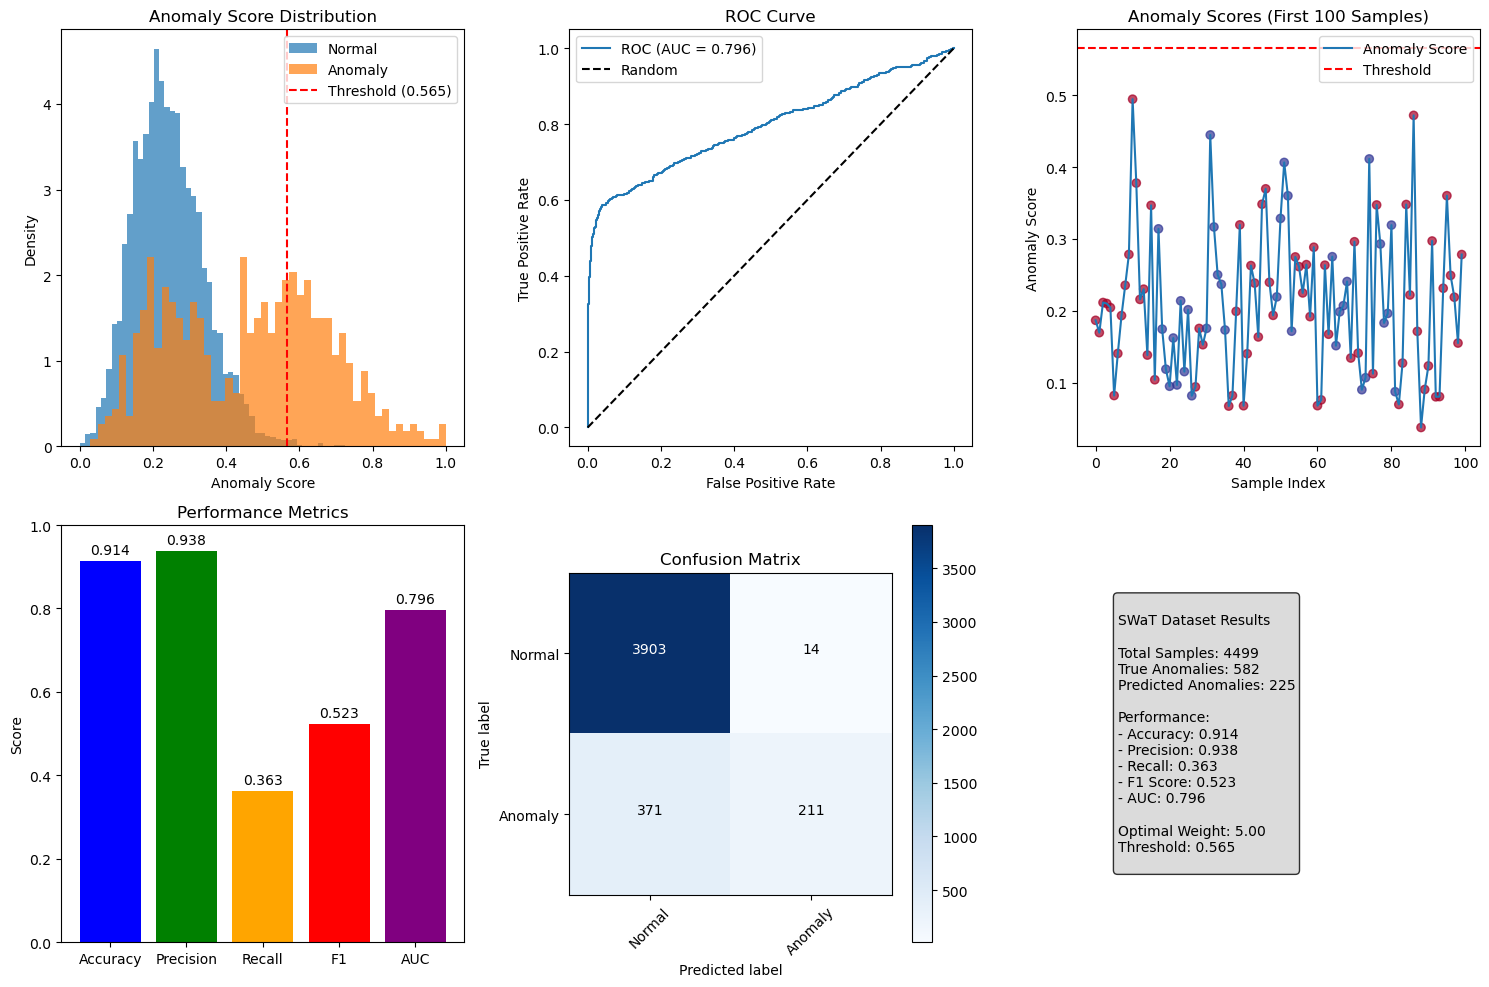

=== 평가 완료 ===


In [27]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pickle as pk
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

# 테스트 데이터 준비
x_tst_np = x_tst_all
lab_tst_np = lab_tst_all

# 라벨 준비 (시퀀스 레벨로 변환)
if lab_tst_np.ndim == 2:
    # 각 시퀀스에서 이상이 하나라도 있으면 이상으로 분류
    sequence_labels = (lab_tst_np.max(axis=1) > 0).astype(int)
else:
    sequence_labels = lab_tst_np

result = simple_evaluate_model(model, x_tst_np, sequence_labels, "SWaT_Dataset")

# 결과 시각화
plt.figure(figsize=(15, 10))

# 이상 점수 분포
plt.subplot(2, 3, 1)
anomaly_scores = result['anomaly_scores']
threshold = result['threshold']
plt.hist(anomaly_scores[sequence_labels == 0], bins=50, alpha=0.7, label='Normal', density=True)
plt.hist(anomaly_scores[sequence_labels == 1], bins=50, alpha=0.7, label='Anomaly', density=True)
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold ({threshold:.3f})')
plt.xlabel('Anomaly Score')
plt.ylabel('Density')
plt.title('Anomaly Score Distribution')
plt.legend()

# ROC 커브
plt.subplot(2, 3, 2)
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(sequence_labels, anomaly_scores)
auc = result['auc']
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()

# 이상 점수 시계열 (처음 100개 샘플)
plt.subplot(2, 3, 3)
sample_scores = anomaly_scores[:100]
sample_labels = sequence_labels[:100]
plt.plot(sample_scores, label='Anomaly Score')
plt.scatter(range(len(sample_scores)), sample_scores, 
           c=sample_labels, cmap='RdYlBu', alpha=0.7)
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')
plt.xlabel('Sample Index')
plt.ylabel('Anomaly Score')
plt.title('Anomaly Scores (First 100 Samples)')
plt.legend()

# 성능 지표
plt.subplot(2, 3, 4)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
values = [result['accuracy'], result['precision'], result['recall'], result['f1'], result['auc']]
colors = ['blue', 'green', 'orange', 'red', 'purple']
bars = plt.bar(metrics, values, color=colors)
plt.ylabel('Score')
plt.title('Performance Metrics')
plt.ylim(0, 1)

# 값 표시
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{value:.3f}', ha='center', va='bottom')

# 혼동 행렬 시각화
plt.subplot(2, 3, 5)
cm = result['confusion_matrix']
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['Normal', 'Anomaly'], rotation=45)
plt.yticks(tick_marks, ['Normal', 'Anomaly'])

# 텍스트 추가
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, format(cm[i, j], 'd'),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.ylabel('True label')
plt.xlabel('Predicted label')

# 이상 탐지 결과 요약
plt.subplot(2, 3, 6)
summary_text = f"""
SWaT Dataset Results

Total Samples: {len(sequence_labels)}
True Anomalies: {np.sum(sequence_labels)}
Predicted Anomalies: {np.sum(result['predictions'])}

Performance:
- Accuracy: {result['accuracy']:.3f}
- Precision: {result['precision']:.3f}
- Recall: {result['recall']:.3f}
- F1 Score: {result['f1']:.3f}
- AUC: {result['auc']:.3f}

Optimal Weight: {result['anomaly_weight']:.2f}
Threshold: {result['threshold']:.3f}
"""
plt.text(0.1, 0.5, summary_text, transform=plt.gca().transAxes, 
         fontsize=10, verticalalignment='center',
         bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.8))
plt.axis('off')

plt.tight_layout()
plt.show()

print("=== 평가 완료 ===")

### Dataset 4 (WADI)

In [ ]:
from datetime import datetime

In [ ]:
normal = pd.read_csv("./datasets/WADI/WADI_14days.csv",sep=',', skiprows=[0,1,2,3],skip_blank_lines=True)
attack = pd.read_csv("./datasets/WADI/WADI_attackdata.csv",sep=",")

In [ ]:
labels=[]

attack.reset_index()
for index, row in attack.iterrows():
    date_temp=row['Date']
    date_mask="%m/%d/%Y"
    date_obj=datetime.strptime(date_temp, date_mask)
    time_temp=row['Time']
    time_mask="%I:%M:%S.%f %p"
    time_obj=datetime.strptime(time_temp,time_mask)

    if date_obj==datetime.strptime('10/9/2017', '%m/%d/%Y'):
        if time_obj>=datetime.strptime('7:25:00.000 PM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('7:50:16.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue

    if date_obj==datetime.strptime('10/10/2017', '%m/%d/%Y'):
        if time_obj>=datetime.strptime('10:24:10.000 AM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('10:34:00.000 AM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('10:55:00.000 AM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('11:24:00.000 AM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('11:30:40.000 AM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('11:44:50.000 AM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('1:39:30.000 PM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('1:50:40.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('2:48:17.000 PM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('2:59:55.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('5:40:00.000 PM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('5:49:40.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('10:55:00.000 AM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('10:56:27.000 AM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
    
    if date_obj==datetime.strptime('10/11/2017', '%m/%d/%Y'):
        if time_obj>=datetime.strptime('11:17:54.000 AM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('11:31:20.000 AM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('11:36:31.000 AM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('11:47:00.000 AM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('11:59:00.000 AM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('12:05:00.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('12:07:30.000 PM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('12:10:52.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('12:16:00.000 PM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('12:25:36.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue
        elif time_obj>=datetime.strptime('3:26:30.000 PM', '%I:%M:%S.%f %p') and time_obj<=datetime.strptime('3:37:00.000 PM', '%I:%M:%S.%f %p'):
            labels.append('Attack')
            continue

    labels.append('Normal')
        